<div class="alert alert-info">
<font size="5"><b>Комментарий ревьюера</b></font>

Привет Иван! Меня зовут Марат, и я буду твоим ревьюером. Проект отправляю обратно из-за множественных ошибок исполнения (Ниже расписал подробнее)

# ML‑модель прогнозирующая вероятность отмены бронирования

<div class="alert alert-danger">
<font size="5"><b>Комментарий ревьюера</b></font>

Ошибка ❌:
    
- Иван, проект пока не получается запустить с чистого ядра в тренажере: не погружены сторонние библиотеки,   eda_template - требуется отдельно получить твой модуль, и файл sentiment_dataset.csv отсутствует в указанном репозитории. Чтобы не было таких ошибок перед сдачей запускает свой проект в тренажёре.
    
    
    
 Чтобы не терять время я пробежался по проекту и подскажу какие ошибки заметил (Наверное это не всё. Но можешь сразу их исправить):
    
    
    
- Добавляем описание столбцов и убираем неиспользуемые импорты

    
- Исключаем брони с нулевой стоимостью (считается что это не внушающий lоверие данные, которые просто удаляем)

 
- Использу нативную обработку категориальных у бустингов


- Согласуем выводы о модели, калибровке, пороге и стабильности с одним актуальным запуском
    
    
    
(В целом работа сильная по объёму исследования и самостоятельности. Думаю не будет каких-то проблем со сдачей)    

<div class="alert alert-info"> <b>Комментарии студента:</b> 
    
Модуль eda_template.py находится по ссылке на проект в GitHub. Добавил ячеку с установкой модуля через репозиторий на GitHub

К сожалению на GitHub нельзя без костылей загрузить файл больше 100 Мб, поэтому вот ссылка на sentiment_dataset.csv https://disk.yandex.ru/d/X5RJlXv9-l2XUg</div>

<div class="alert alert-info"> <b>Комментарии студента:</b> 
    
1. Не используемые импорты убрал.

2. **Описание каких столбцов нужно добавить? Столбцов двух таблиц? Если да, то на мой взгляд такое требование излишне, слишком загромаждает отчет и не понятна его роль**

3. Исключил бронирования с нулевой стоимостью

4. Сделал нативную обработку категоральных, но это усложнило код. Возможно как-то это реализовать проще?

5. Выводы скорректированы

</div>

---
Пуршев Иван Александрович

23.09.2026

проект и вспомогательыне модули и datasets на GitHub:
https://github.com/iven4eg/YP_Project_m4.git

---

**Цели и задачи:**
Разработать модель(и) предсказывающую вероятность отмены брони по входным данным, что позволит компании принимать обоснованные решения о повторном бронировании или сохранении брони.

Экономическую эффективность модели необходимо оценить по следующим показателя:
- динамику доли отмен бронирования;
- динамику загрузки отелей;
 - прирост дохода благодаря модели

**Даныне для разработки:**
1. Таблица с данными об истории бронирования `hotel_bookings`.
Данные содержат информацию о бронированиях номеров в гостинице. Каждая строка — это отдельная бронь, а столбцы хранят параметры бронирования. Всего в таблице 35 341 случай бронирования.
2. Таблица с отзывами о проживании `hotel_reviews`.
Данные содержат информацию об отзывах гостей, которые заселялись в отель. Всего в ней 25 177 отзывов о проживании. Некоторые гости приезжали в отели сети много раз, поэтому могли оставить несколько отзывов.

---

## Перевод бизнес-задачи на язык машинного обучения

- Напишите, что конкретно будете делать с точки зрения Data Science: расскажите, какие модели и методы вы планируете применить для решения задачи.

Для прогнозирования отмены бронирования будет решаться задача **бинарной классификации**: целевой признак — факт отмены бронирования, где 1 означает отмену, а 0 — сохранение брони.

На первом этапе будут загружены данные о бронированиях и отзывах клиентов из PostgreSQL с помощью `SQLAlchemy` и SQL-запросов. Затем будет проведён исследовательский анализ данных.

Для моделирования будут выбраны как минимум две модели на основе деревьев решений: 
- `RandomForestClassifier` — базовая ансамблевая модель, объединяющая множество деревьев и снижающая риск переобучения за счёт усреднения их результатов;
- градиентный бустинг — `CatBoostClassifier` или `LightGBMClassifier`.

Данные будут разбиты на 3 выборки: Обучающая (60%), Калибровочная (20%) и Тестовая (20%).

Гиперпараметры моделей будут подбираться с помощью Optuna и кросс-валидации из трёх фолдов.

Ключевой метрикой для отбора модели будет Incremental Revenue (IR),т.к. модель должна не просто находить отмены, а приносить отелю максимальную дополнительную выручку с учётом стоимости ошибочных решений.

После выбора лучшей модели её вероятностные предсказания будут откалиброваны на калибровочной выборке.

Затем на калибровочной выборке будет найден оптимальный порог классификации: значение вероятности отмены, выше которого бронирование будет считаться рискованным.

Финальная модель будет проверена на тестовой выборке и проведен аанлиз важности признаков

## Загрузка необходимых библиотек

- Загрузите всё, что планируете использовать для выполнения проекта.

In [ ]:
# установка и обновление библиотек
import sys
!"{sys.executable}" -m pip install phik, optuna, shap
!"{sys.executable}" -m pip install --upgrade scikit-learn

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine
from sqlalchemy.exc import OperationalError

import phik

import re
import nltk
nltk.download('stopwords') # Скачиваем все существующие стоп-слова
from nltk.corpus import stopwords # Импортируем стоп-слова
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import optuna

from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay, calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

import shap

[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.


In [ ]:
# установка модуля с функциями для EDA
!"{sys.executable}" -m pip install --no-deps git+https://github.com/iven4eg/eda_template.git

In [2]:
# загрузка совего модуля с функциями для EDA
import eda_template

In [3]:
# Базовые настройки отображения для ноутбука
pd.set_option('display.max_columns', None) # сколько колонок DataFrame pandas показывает при выводе
pd.set_option('display.max_rows', 200) # максимальным числом строк, которое pandas показывает при выводе DataFrame
sns.set_theme(style='whitegrid') # белый фон с сеткой (grid) по осям

# --- ГЛОБАЛЬНЫЕ ПАРАМЕТРЫ ---
RANDOM_STATE = 108

## Этап 1: подготовка данных

### Загрузка данных

- Все данные о работе сети отелей хранятся в базе данных на сервере. Для работы с ними в Python используйте библиотеку SQLAlchemy, чтобы выгрузить данные SQL-запросом.

- Сделайте выводы о проделанной работе.

Параметры для подключения к данным PostgreSQL:

- **Хост:** rc1b-wcoijxj3yxfsf3fs.mdb.yandexcloud.net

- **База данных:** data-scientist-hotels

- **Порт:** 6432

- **Пользователь:** praktikum_student

- **Пароль:** Sdf4$2;d-d30pp

Названия нужных вам таблиц — `hotel_bookings` (таблица бронирований) и `hotel_reviews` (таблица отзывов).

In [4]:
# подключаемся к БД
# параметры подключения
db_config = {'user': 'praktikum_student', # имя пользователя
             'pwd': 'Sdf4$2;d-d30pp', # пароль
             'host': 'rc1b-wcoijxj3yxfsf3fs.mdb.yandexcloud.net',
             'port': 6432, # порт подключения
             'db': 'data-scientist-hotels',
             }

# строка подключения
connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
) 

# создание соединения
engine = create_engine(connection_string) 

In [5]:
try:
    # извлечение данных
    query_booking = '''
    SELECT *
    FROM hotel_bookings
    '''
    
    query_reviews = '''
    SELECT *
    FROM hotel_reviews
    '''
    
    df_booking = pd.read_sql_query(query_booking, con=engine)
    df_reviews = pd.read_sql_query(query_reviews, con=engine)
except OperationalError as err:
    print(f'Ошибка подключения к БД: {err}')
    if hasattr(err, 'orig'):
            print(f'Код ошибки PostgreSQL: {err.orig.diag.sqlstate}')
    # Загрузка таблиц с диска
    file_path = Path('datasets') 
    df_booking = pd.read_csv(file_path / 'hotel_bookings.csv', sep=',', decimal='.')
    df_reviews = pd.read_csv(file_path / 'hotel_reviews.csv', sep=',', decimal='.')

Ошибка подключения к БД: (psycopg2.OperationalError) could not translate host name "rc1b-wcoijxj3yxfsf3fs.mdb.yandexcloud.net" to address: Name or service not known

(Background on this error at: https://sqlalche.me/e/20/e3q8)
Код ошибки PostgreSQL: None


In [6]:
# Выводим первые строки датафреймов на экран
display(df_booking.head(2))
display(df_reviews.head(2))

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1


,customer_id,booking_id,review_date,stay_rating,review_text
0,C0001,INN00000,2020-08-21,3,"Неплохо. тихо и спокойно, но отсутствие фена в..."
1,C0001,INN00001,2021-10-15,3,"Неплохо. красивое оформление территории, но не..."


### Исследовательский анализ данных и предобработка

- Проведите EDA, используя один из следующих инструментов на ваш выбор:

    - библиотеку pandas;
    - SQL-запросы.
    
- EDA должен включать:
    - аналитическое исследование;
    - графическое исследование для количественных данных и для категориальных данных.

- Сделайте выводы о выбросах, пропусках, дубликатах и других аномалиях  в каждой таблице.
- Проведите необходимую предобработку данных.

In [7]:
# вызываем быстрый анализ из своего модуля
eda_template.quick_eda(df_booking, exclude_cols=['booking_id'])

#### Quick EDA

Размер датасета: (35341, 17)
Информация по датасету:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35341 entries, 0 to 35340
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   booking_id                 35341 non-null  object 
 1   booking_date               35341 non-null  object 
 2   sales_channel              35341 non-null  object 
 3   adult_count                35341 non-null  int64  
 4   child_count                35341 non-null  int64  
 5   returning_customer         35341 non-null  bool   
 6   previous_cancellations     35341 non-null  int64  
 7   previous_no_shows          35341 non-null  int64  
 8   booking_status             35341 non-null  object 
 9   booking_value              35341 non-null  float64
 10  days_until_checkin         35341 non-null  int64  
 11  weekday_nights             35341 non-null  int64  
 12  weekend_nights             35341 non-null  int64 

None


Первые строки:


,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,0
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.0,150,6,2,тип_питания_1,False,тип_1,0
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,1



Сводка по колонкам:


,dtype,n_unique,n_missing,missing_%
returning_customer,bool,2,0,0.0
booking_status,object,2,0,0.0
parking_included,bool,2,0,0.0
sales_channel,object,3,0,0.0
child_count,int64,3,0,0.0
weekend_nights,int64,4,0,0.0
meal_plan,object,5,0,0.0
adult_count,int64,6,0,0.0
previous_cancellations,int64,6,0,0.0
previous_no_shows,int64,6,0,0.0



Число дубликатов: 4608

Типы признаков:
Числовые: 3
Категориальные: 13
Datetime: 0
Числовые, трактуемые как категории: ['adult_count', 'child_count', 'previous_cancellations', 'previous_no_shows', 'weekend_nights', 'customer_special_requests']


##### Числовые признаки: describe()

,count,mean,std,min,25%,50%,75%,max
booking_value,35341.0,61634.055219,42837.589968,0.0,33500.0,53600.0,80400.0,417221.2
days_until_checkin,35341.0,100.523726,71.872677,2.0,45.0,90.0,144.0,300.0
weekday_nights,35341.0,6.532922,3.339492,1.0,5.0,6.0,9.0,15.0


##### Категориальные признаки

,n_unique,top_value
booking_status,2,нет_отказа
returning_customer,2,True
parking_included,2,False
sales_channel,3,офлайн_бронирование
child_count,3,0
weekend_nights,4,2
meal_plan,5,тип_питания_1
adult_count,6,1
customer_special_requests,6,0
previous_no_shows,6,0


##### Пропуски

Пропусков не найдено.


In [8]:
eda_template.quick_eda(df_reviews, exclude_cols=['customer_id', 'booking_id'])

#### Quick EDA

Размер датасета: (25177, 5)
Информация по датасету:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25177 entries, 0 to 25176
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  25177 non-null  object
 1   booking_id   25177 non-null  object
 2   review_date  25177 non-null  object
 3   stay_rating  25177 non-null  int64 
 4   review_text  25177 non-null  object
dtypes: int64(1), object(4)
memory usage: 983.6+ KB


None


Первые строки:


,customer_id,booking_id,review_date,stay_rating,review_text
0,C0001,INN00000,2020-08-21,3,"Неплохо. тихо и спокойно, но отсутствие фена в..."
1,C0001,INN00001,2021-10-15,3,"Неплохо. красивое оформление территории, но не..."
2,C0001,INN00002,2023-03-08,4,Отличный отель! удобные парковочные места. зде...
3,C0002,INN00003,2017-08-13,3,"Неплохо. тёплый приём, но неисправная сантехни..."
4,C0003,INN00004,2019-07-12,4,Отличный отель! качественная косметика в ванно...



Сводка по колонкам:


,dtype,n_unique,n_missing,missing_%
stay_rating,int64,4,0,0.0
review_date,object,2514,0,0.0
customer_id,object,13429,0,0.0
review_text,object,14153,0,0.0
booking_id,object,21883,0,0.0



Число дубликатов: 0

Типы признаков:
Числовые: 0
Категориальные: 3
Datetime: 0
Числовые, трактуемые как категории: ['stay_rating']


##### Категориальные признаки

,n_unique,top_value
stay_rating,4,3
review_date,2514,2020-06-12
review_text,14153,Отличный отель! хорошие виды из окон.


##### Пропуски

Пропусков не найдено.


---
Приведем признаки `booking_date` и `review_date` к типу дата

---

In [9]:
df_booking = df_booking.copy()
df_booking['booking_date'] = pd.to_datetime(df_booking['booking_date'])

df_reviews = df_reviews.copy()
df_reviews['review_date'] = pd.to_datetime(df_reviews['review_date'])

In [11]:
num_features_b, cat_features_b, dt_features_b, numeric_as_features_b = eda_template.eda_template._get_types(df_booking, cat_threshold=2)
num_features_r, cat_features_r, dt_features_r, numeric_as_features_r = eda_template.eda_template._get_types(df_reviews, cat_threshold=2)

,count,mean,std,min,25%,50%,75%,max
adult_count,35341.0,12.479726,45.726290,1.0,1.0,2.0,3.0,300.0
child_count,35341.0,0.358988,0.587324,0.0,0.0,0.0,1.0,2.0
previous_cancellations,35341.0,0.356923,0.628771,0.0,0.0,0.0,1.0,5.0
previous_no_shows,35341.0,0.839535,0.931724,0.0,0.0,1.0,1.0,5.0
booking_value,35341.0,61634.055219,42837.589968,0.0,33500.0,53600.0,80400.0,417221.2
days_until_checkin,35341.0,100.523726,71.872677,2.0,45.0,90.0,144.0,300.0
weekday_nights,35341.0,6.532922,3.339492,1.0,5.0,6.0,9.0,15.0
weekend_nights,35341.0,1.953991,1.477249,0.0,0.0,2.0,2.0,6.0
customer_special_requests,35341.0,0.621488,0.784391,0.0,0.0,0.0,1.0,5.0


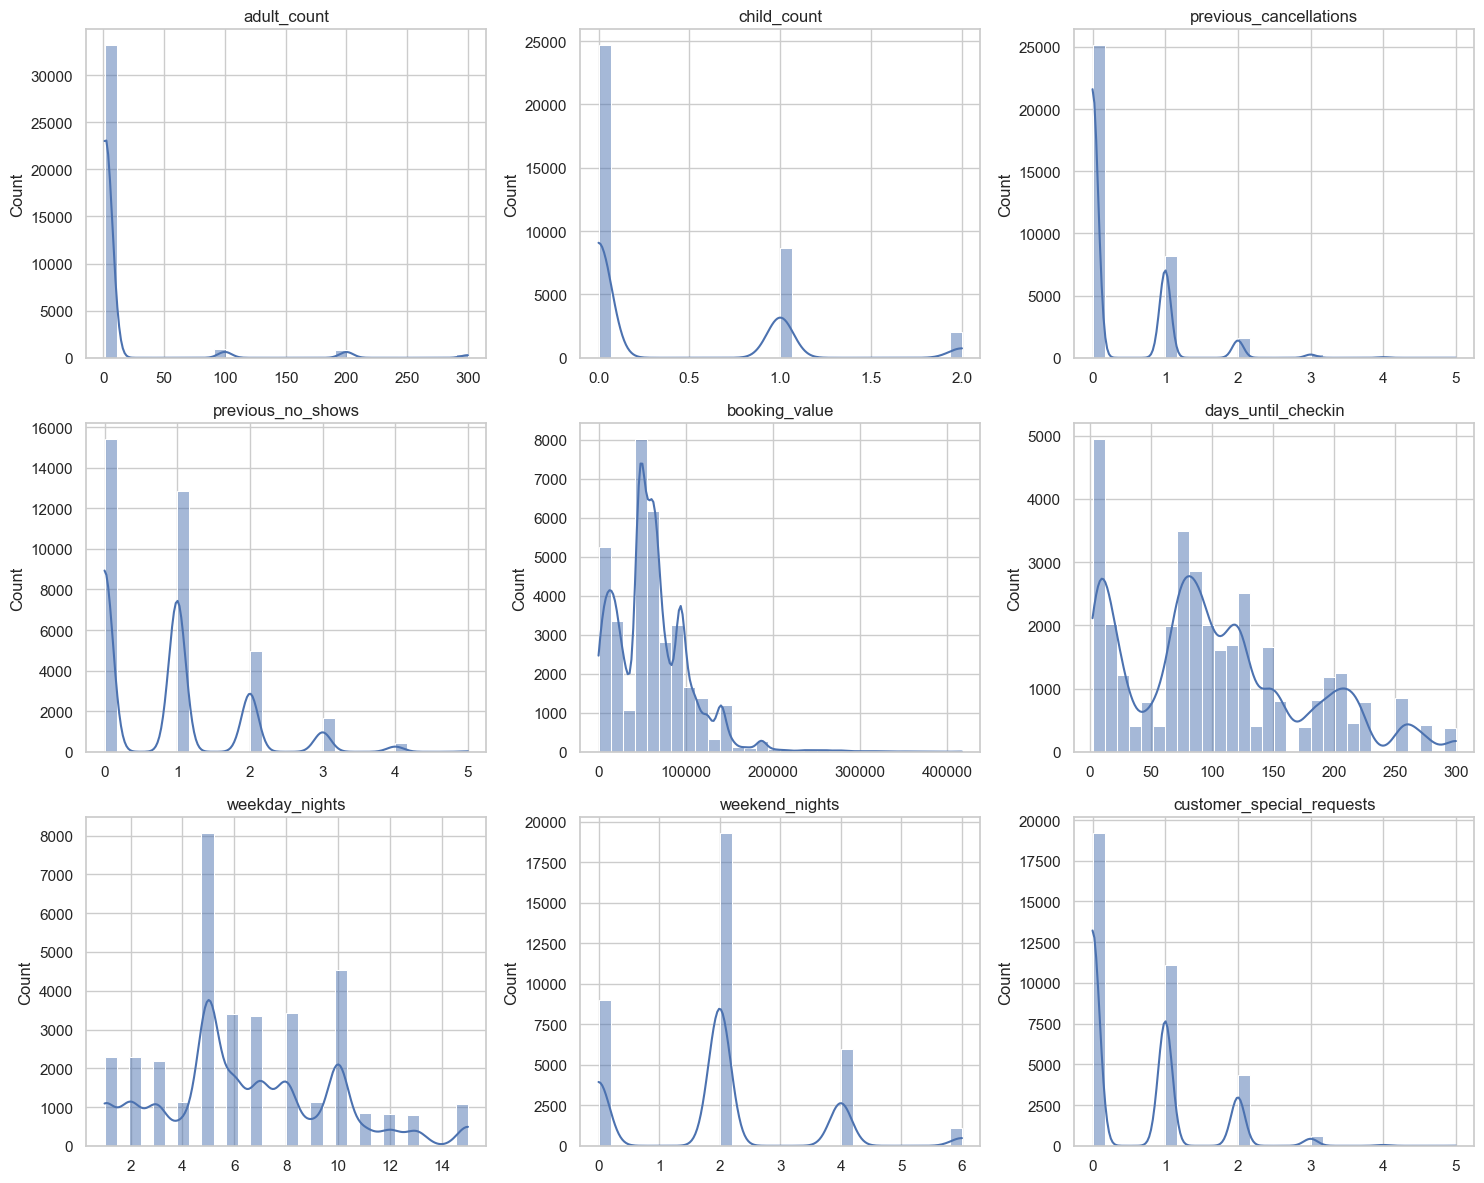

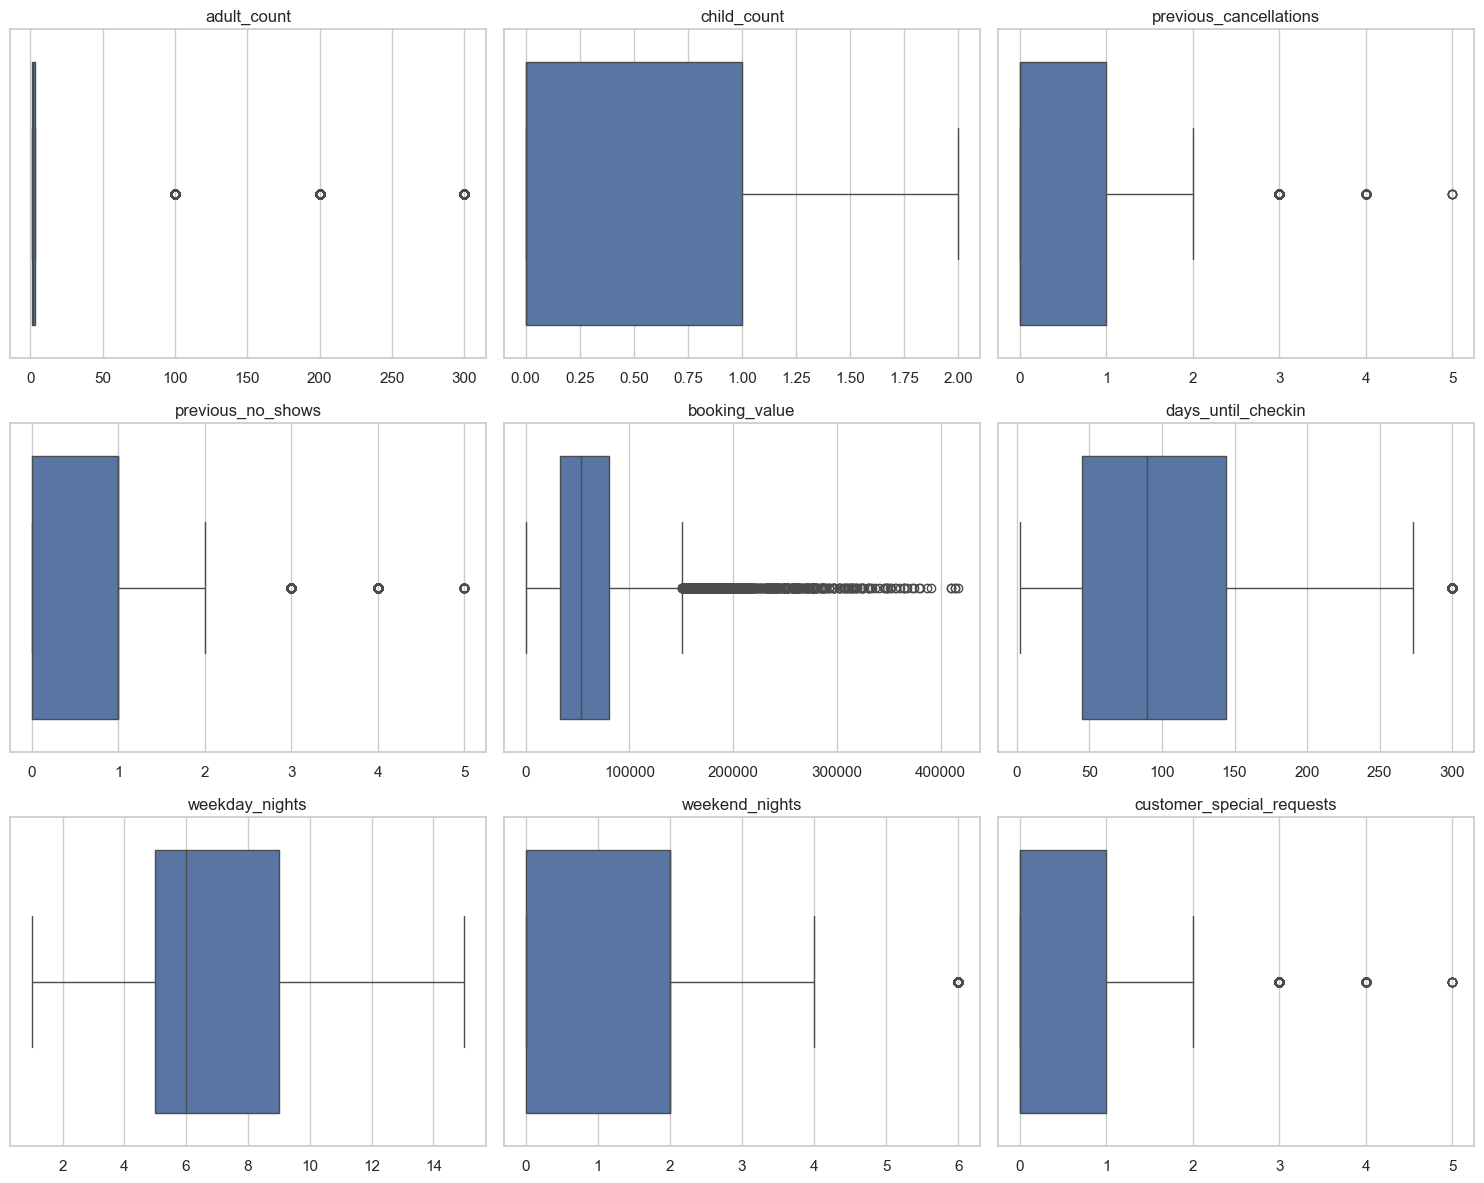

In [13]:
display(df_booking[num_features_b].describe().T)

eda_template.eda_template._plot_numeric(df_booking, num_features_b)
eda_template.eda_template._plot_boxplots(df_booking, num_features_b)

,count,mean,std,min,25%,50%,75%,max
stay_rating,25177.0,3.395321,0.541434,2.0,3.0,3.0,4.0,5.0


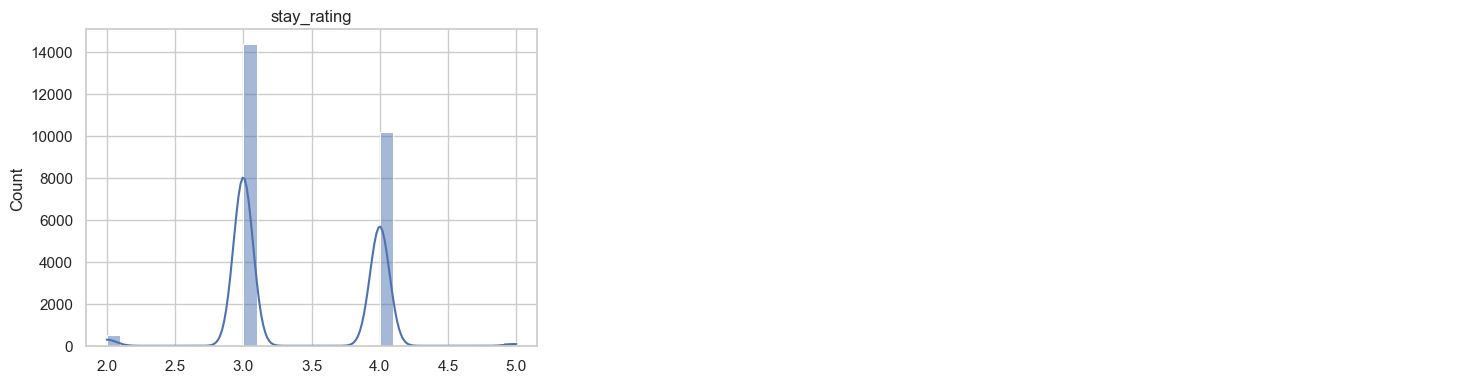

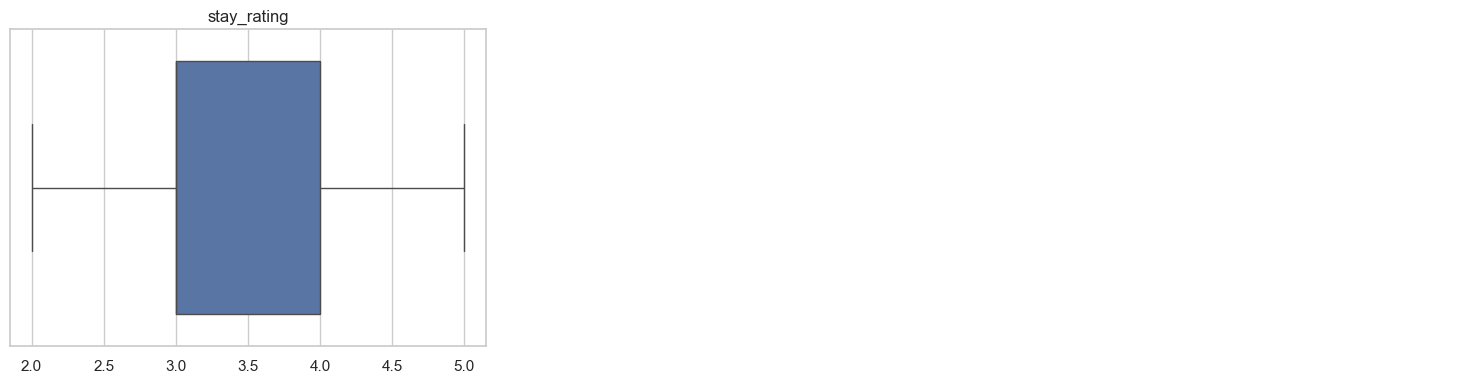

In [14]:
display(df_reviews[num_features_r].describe().T)

eda_template.eda_template._plot_numeric(df_reviews, num_features_r)
eda_template.eda_template._plot_boxplots(df_reviews, num_features_r)

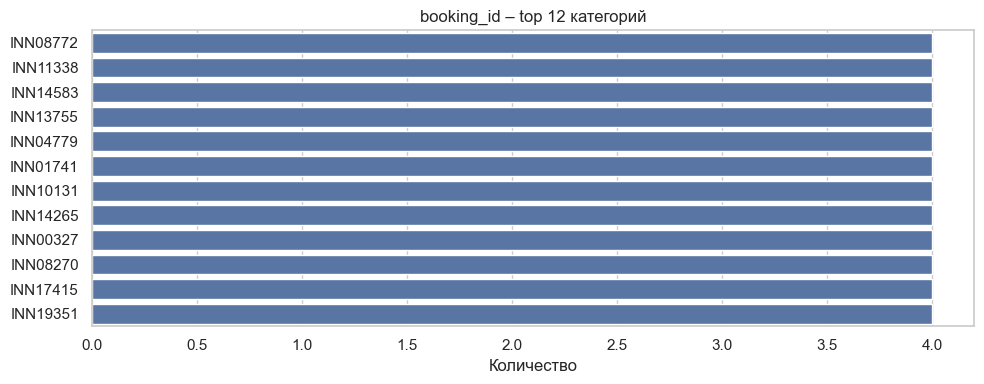

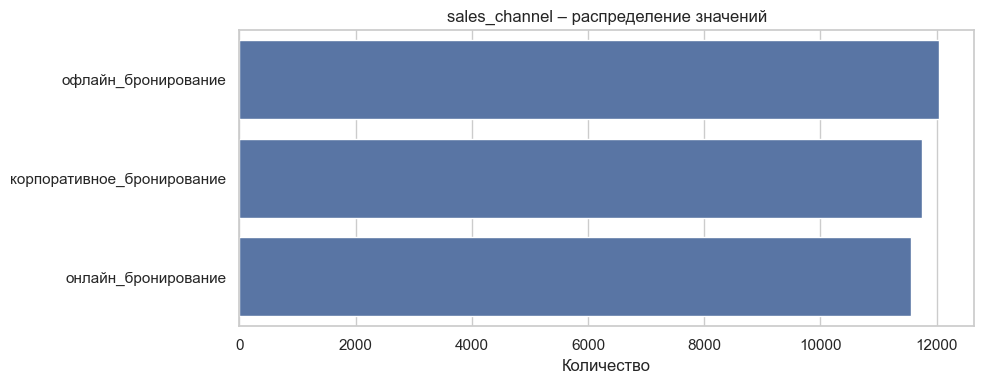

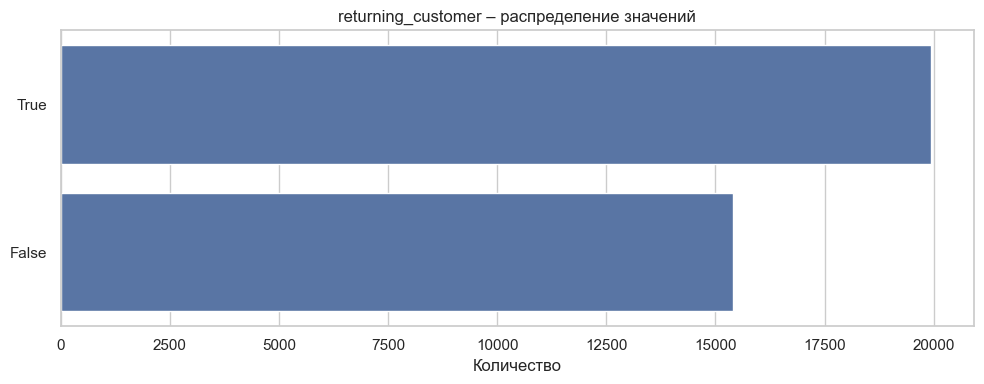

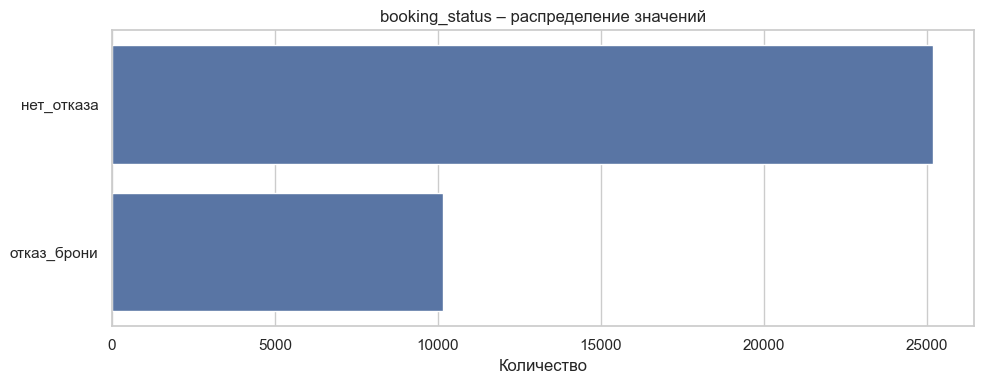

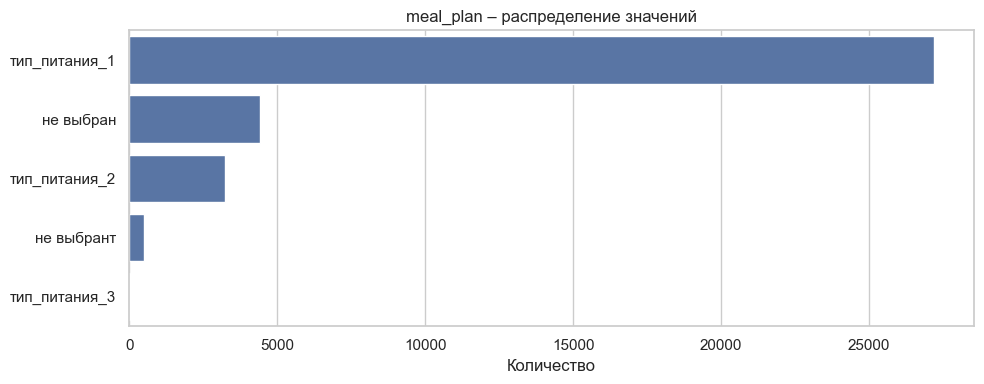

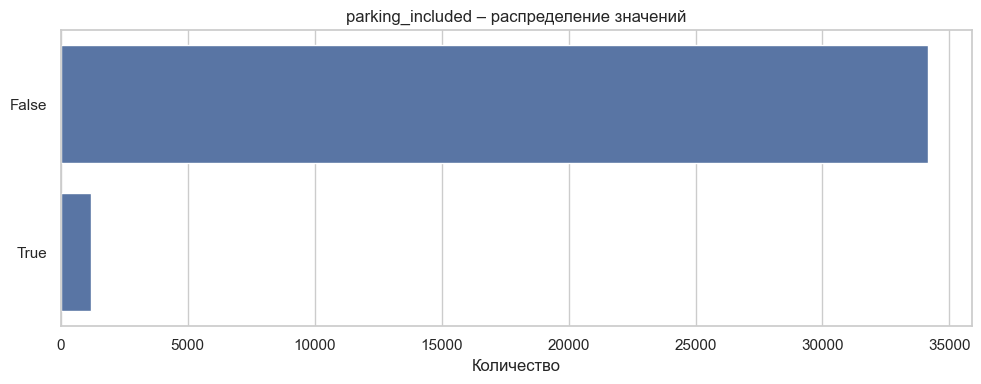

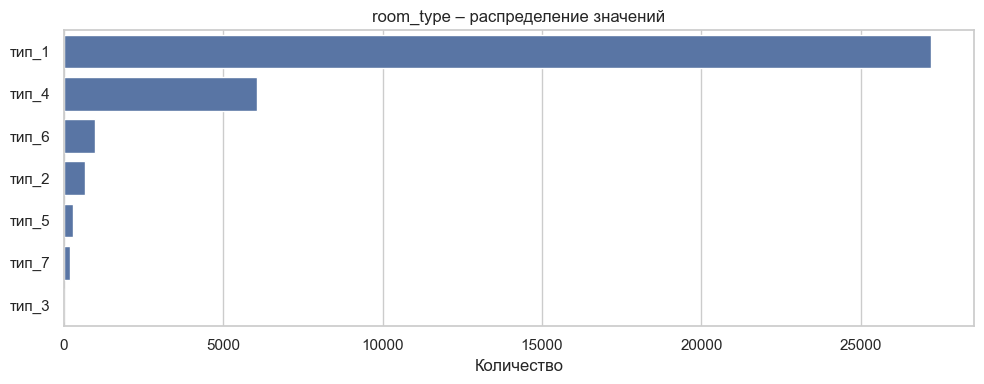

In [15]:
eda_template.eda_template._plot_categorical(df_booking, cat_features_b)

**Выводы по таблице `hotel_bookings`:**
1. В Таблице обнаружено 4608 дубликатов (13,3 % от всего объема). Данные строки будут удалены.
2. Проупуски в данных не выявлены.
3. Выявлены выбросы у признака `adult_count`. У остальных признаков завышенные значения не считаются выбросами, т.к. соответсвуют значению признака.
4. В признаке `meal_plan` выявлены ошибки в написании 'не выбран'. Скорректируем признак.
5. Нулевые значения в признаке `booking_value`cчитаем не внушающими доверия данными. Удалим данные строки.

In [16]:
df_booking['meal_plan'] = df_booking['meal_plan'].replace('не выбрант', 'не выбран')

In [17]:
df_booking = df_booking[df_booking['booking_value'] != 0]

In [18]:
df_booking[df_booking.duplicated(keep=False)]

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
7,INN00007,2017-08-21,корпоративное_бронирование,2,0,True,1,1,нет_отказа,67000.0,144,8,2,тип_питания_1,False,тип_4,0
13,INN00013,2021-10-22,онлайн_бронирование,3,2,True,0,1,отказ_брони,53600.0,76,6,2,тип_питания_1,False,тип_6,1
22,INN00022,2020-03-02,корпоративное_бронирование,3,0,True,0,3,отказ_брони,33500.0,77,5,0,тип_питания_1,False,тип_4,1
27,INN00027,2020-08-21,корпоративное_бронирование,2,1,False,0,0,нет_отказа,80400.0,150,10,2,не выбран,False,тип_4,0
48,INN00048,2018-05-20,офлайн_бронирование,2,0,False,0,0,нет_отказа,67000.0,11,8,2,не выбран,False,тип_4,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35335,INN18749,2018-11-16,офлайн_бронирование,2,0,False,0,0,отказ_брони,6700.0,71,1,0,тип_питания_1,False,тип_1,0
35336,INN00327,2020-07-21,онлайн_бронирование,2,1,True,1,1,отказ_брони,13400.0,259,2,0,тип_питания_1,False,тип_4,0
35337,INN13369,2018-11-12,офлайн_бронирование,1,0,False,0,0,нет_отказа,13400.0,192,2,0,тип_питания_1,False,тип_1,2
35338,INN29068,2019-11-03,корпоративное_бронирование,2,2,False,0,0,нет_отказа,60300.0,109,7,2,тип_питания_1,False,тип_1,1


In [19]:
df_booking[df_booking['booking_id'] == 'INN26845']

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
26850,INN26845,2019-02-08,корпоративное_бронирование,2,0,False,0,0,нет_отказа,46900.0,122,5,2,не выбран,False,тип_1,0
35340,INN26845,2019-02-08,корпоративное_бронирование,2,0,False,0,0,нет_отказа,46900.0,122,5,2,не выбран,False,тип_1,0


In [20]:
df_booking_clear = df_booking.copy()
print('Размер до удаления:', df_booking.shape[0])

df_booking_clear = df_booking_clear.drop_duplicates().reset_index(drop=True)
print(f'Размер после удаления: {df_booking_clear.shape[0]}')

Размер до удаления: 33920
Размер после удаления: 29504


In [21]:
# Анализ выбросов
big_bookings = df_booking_clear[df_booking_clear['adult_count'] >= 100]
big_bookings

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0
43,INN00044,2018-09-25,онлайн_бронирование,200,1,True,1,1,нет_отказа,173223.4,130,13,4,тип_питания_1,False,тип_4,1
78,INN00079,2022-08-11,офлайн_бронирование,100,0,True,2,2,нет_отказа,117039.7,73,8,2,тип_питания_1,False,тип_1,1
82,INN00083,2020-03-25,корпоративное_бронирование,200,1,False,0,0,нет_отказа,46900.0,79,5,2,тип_питания_1,False,тип_4,1
89,INN00090,2017-09-08,офлайн_бронирование,100,2,False,0,0,отказ_брони,33500.0,217,5,0,не выбран,False,тип_1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29322,INN30545,2018-05-28,онлайн_бронирование,100,0,False,0,0,нет_отказа,210833.2,150,10,2,тип_питания_1,False,тип_1,0
29334,INN30558,2019-03-21,офлайн_бронирование,100,1,False,0,0,нет_отказа,60300.0,55,7,2,не выбран,False,тип_4,2
29407,INN30632,2020-06-03,офлайн_бронирование,100,0,True,1,1,нет_отказа,53600.0,3,6,2,тип_питания_1,False,тип_4,0
29408,INN30633,2021-10-14,офлайн_бронирование,100,0,True,1,2,отказ_брони,46900.0,257,5,2,не выбран,False,тип_1,0


In [22]:
# какие именно большие значения встречаются
big_bookings['adult_count'].value_counts().sort_index()

adult_count
100    848
200    830
300    376
Name: count, dtype: int64

In [23]:
# количество строк с выбросами не корпаративное бронирование
big_bookings[big_bookings['sales_channel'] != 'корпоративное_бронирование'].shape[0]

1360

In [24]:
big_bookings[['adult_count', 'weekday_nights', 'room_type', 'sales_channel', 'booking_value']].head(10)

,adult_count,weekday_nights,room_type,sales_channel,booking_value
0,300,1,тип_1,корпоративное_бронирование,6700.0
43,200,13,тип_4,онлайн_бронирование,173223.4
78,100,8,тип_1,офлайн_бронирование,117039.7
82,200,5,тип_4,корпоративное_бронирование,46900.0
89,100,5,тип_1,офлайн_бронирование,33500.0
97,100,6,тип_1,корпоративное_бронирование,53600.0
108,100,2,тип_1,онлайн_бронирование,17800.0
139,100,10,тип_1,офлайн_бронирование,93800.0
141,200,5,тип_2,корпоративное_бронирование,33500.0
155,200,5,тип_1,корпоративное_бронирование,46900.0


In [25]:
# Cколько больших броней их по каждому каналу
print(f"Распределение у больших бронированией:\n {big_bookings['sales_channel'].value_counts()}")

print(f"\nРаспределение во всем датасете:\n {df_booking_clear['sales_channel'].value_counts()}")

Распределение у больших бронированией:
 sales_channel
корпоративное_бронирование    694
офлайн_бронирование           681
онлайн_бронирование           679
Name: count, dtype: int64

Распределение во всем датасете:
 sales_channel
офлайн_бронирование           10023
корпоративное_бронирование     9817
онлайн_бронирование            9664
Name: count, dtype: int64


In [26]:
# Группируем по типу номера и смотрим максимум по adult_count
max_people_per_type = big_bookings.groupby('room_type')['adult_count'].max()
max_people_per_type.sort_values(ascending=False)

room_type
тип_1    300
тип_2    300
тип_4    300
тип_6    300
тип_5    300
тип_7    200
тип_3    100
Name: adult_count, dtype: int64

In [27]:
# Группируем по типу номера и смотрим максимум по adult_count
norm_bookings = df_booking_clear[df_booking_clear['adult_count'] < 100]
max_people_per_type = norm_bookings.groupby('room_type')['adult_count'].max()
max_people_per_type.sort_values(ascending=False)

room_type
тип_1    3
тип_2    3
тип_4    3
тип_6    3
тип_5    3
тип_7    3
тип_3    2
Name: adult_count, dtype: int64

In [28]:
# Сравнение медианы и доли между двумя группами 

df_booking_clear.assign(
    adult_group=np.where(
        df_booking_clear['adult_count'] >= 100,
        'более_100',
        'до_100'
    )
).groupby('adult_group').agg(
    n=('booking_id', 'count'),
    adult_median=('adult_count', 'median'),
    children_median=('child_count', 'median'),
    booking_value_median=('booking_value', 'median'),
    lead_time_median=('days_until_checkin', 'median'),
    weekday_nights_median=('weekday_nights', 'median'),
    weekend_nights_median=('weekend_nights', 'median'),
    returning_customer_share=('returning_customer', 'mean'),
    previous_cancellations_median=('previous_cancellations', 'median')
)

,n,adult_median,children_median,booking_value_median,lead_time_median,weekday_nights_median,weekend_nights_median,returning_customer_share,previous_cancellations_median
adult_group,,,,,,,,,
более_100,2054,200.0,0.0,60300.0,90.0,6.0,2.0,0.571081,0.0
до_100,27450,2.0,0.0,60300.0,90.0,6.0,2.0,0.563825,0.0


**Выводы по выбрасам:**

В признаке `adult_count` выявлены аномальные значения 100, 200 и 300, кратные 100. Сравнение распределений и медианных значений других признаков для бронирований с `adult_count >= 100` и остальных бронирований не выявило существенных различий. Следовательно, большие значения являются ошибкой масштаба и будут скорректированы делением на 100.


In [29]:
mask = df_booking_clear['adult_count'] >= 100

df_booking_clear.loc[mask, 'adult_count'] = (
    df_booking_clear.loc[mask, 'adult_count'] / 100
)

### Объединение таблиц

- Соедините таблицу отзывов с таблицей бронирований. Руководствуйтесь правилом: для каждой даты бронирования в столбце `booking_date` нужно взять комментарий и оценку клиента по предыдущей ближайшей дате отзывов, указанной в столбце `review_date`. Это позволит связать обратную связь клиента с конкретным периодом проживания, что критически важно для анализа удовлетворённости гостей.

- Сделайте выводы о том, как прошло объединение и что получилось в результате.

In [30]:
df_booking_clear.groupby('booking_date')['booking_id'].count()

booking_date
2017-01-01     9
2017-01-02    12
2017-01-03    11
2017-01-04     9
2017-01-05    14
              ..
2025-06-30     1
2025-07-01     2
2025-07-04     1
2025-10-02     1
2025-10-22     1
Name: booking_id, Length: 2440, dtype: int64

In [31]:
df_booking_clear[df_booking_clear['booking_date'] == '2017-01-01']

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
170,INN00177,2017-01-01,онлайн_бронирование,2,0,False,0,0,отказ_брони,67000.0,73,8,2,тип_питания_2,False,тип_1,0
7501,INN07784,2017-01-01,онлайн_бронирование,2,0,False,0,0,отказ_брони,166363.4,87,12,4,тип_питания_2,False,тип_1,0
11379,INN11824,2017-01-01,корпоративное_бронирование,3,0,False,0,0,нет_отказа,6700.0,63,1,0,тип_питания_1,False,тип_4,1
13929,INN14477,2017-01-01,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,85,5,2,тип_питания_1,True,тип_1,2
16721,INN17387,2017-01-01,офлайн_бронирование,2,0,True,1,1,нет_отказа,73700.0,79,9,2,тип_питания_1,False,тип_1,2
19240,INN20018,2017-01-01,онлайн_бронирование,3,0,True,1,1,отказ_брони,46900.0,83,5,2,тип_питания_1,False,тип_1,2
20898,INN21754,2017-01-01,онлайн_бронирование,3,2,False,0,0,нет_отказа,67000.0,124,8,2,тип_питания_2,False,тип_2,0
21565,INN22445,2017-01-01,офлайн_бронирование,2,0,False,0,0,нет_отказа,71200.0,85,6,2,не выбран,False,тип_1,0
27780,INN28926,2017-01-01,онлайн_бронирование,3,0,False,0,0,отказ_брони,89000.0,85,8,2,тип_питания_1,False,тип_1,1


In [32]:
df_reviews[df_reviews['booking_id'] == 'INN21754']

,customer_id,booking_id,review_date,stay_rating,review_text
15503,C11662,INN21754,2017-06-07,3,"Неплохо. удобный трансфер из аэропорта, но дол..."
24791,C11662,INN21754,2017-05-29,4,Отличный отель! аккуратный сад. сервис выше вс...
24994,C11662,INN21754,2017-06-08,4,Отличный отель! свежее постельное бельё. Дети ...


In [33]:
# Проверка один ли customer_id у каждой брони
booking_customer_count = df_reviews.groupby('booking_id')['customer_id'].nunique()

print('Максимум разных customer_id на один booking_id:', booking_customer_count.max())

print('Броней с несколькими customer_id:', (booking_customer_count > 1).sum())

Максимум разных customer_id на один booking_id: 1
Броней с несколькими customer_id: 0


In [34]:
reviews_per_booking = df_reviews['booking_id'].value_counts()

print('Максимум отзывов на одну бронь:', reviews_per_booking.max())
print('Броней с несколькими отзывами:', (reviews_per_booking > 1).sum())

Максимум отзывов на одну бронь: 4
Броней с несколькими отзывами: 3025


In [35]:
# одна строка — одна бронь — один клиент.
booking_customer_map = df_reviews[['booking_id', 'customer_id']].drop_duplicates()

In [36]:
# Присоединение клиента к таблице бронирований:
df_bookings_customer = df_booking_clear.merge(
    booking_customer_map,
    on='booking_id',
    how='left',
    validate='one_to_one'
)

In [37]:
print(
    'Повторяющихся booking_id в справочнике:',
    booking_customer_map['booking_id'].duplicated().sum()
)

Повторяющихся booking_id в справочнике: 0


In [38]:
print('Строк до объединения:', df_booking_clear.shape[0])
print('Строк после объединения:', df_bookings_customer.shape[0])

print(f"Доля бронирований с customer_id: {df_bookings_customer['customer_id'].notna().mean():.1%}")
print(f"Число бронирований без customer_id: {df_bookings_customer['customer_id'].isna().sum()}")

Строк до объединения: 29504
Строк после объединения: 29504
Доля бронирований с customer_id: 71.2%
Число бронирований без customer_id: 8492


In [39]:
# Сохранение исходного порядка строк

df_bookings_customer = df_bookings_customer.copy()
df_bookings_customer['_row_id'] = range(len(df_bookings_customer))
df_bookings_customer

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests,customer_id,_row_id
0,INN00000,2020-07-08,корпоративное_бронирование,3,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0,C0001,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1,C0001,1
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,0,C0001,2
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.0,150,6,2,тип_питания_1,False,тип_1,0,C0002,3
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,1,C0003,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29499,INN30727,2020-03-05,корпоративное_бронирование,1,0,False,0,0,отказ_брони,89000.0,210,8,2,не выбран,False,тип_1,0,NaN,29499
29500,INN30728,2020-04-08,корпоративное_бронирование,1,0,False,1,0,нет_отказа,13400.0,7,2,0,тип_питания_1,False,тип_1,2,C16473,29500
29501,INN30729,2017-01-31,корпоративное_бронирование,1,2,False,0,0,нет_отказа,6700.0,50,1,0,тип_питания_2,False,тип_1,1,C16474,29501
29502,INN30730,2019-10-11,офлайн_бронирование,1,1,False,0,0,нет_отказа,53600.0,15,6,2,тип_питания_1,False,тип_1,1,C16475,29502


In [40]:
# Сортировка по временному ключу для merge_asof()
reviews_for_merge = df_reviews[['customer_id', 'review_date', 'stay_rating', 'review_text']].copy()

bookings_sorted = df_bookings_customer.sort_values(['booking_date', 'customer_id'])
reviews_sorted = reviews_for_merge.sort_values(['review_date', 'customer_id'])

In [41]:
'''
merge_asof() соединяет данные по ближайшему временному ключу
direction='backward' выбирает последнюю дату review_date, которая предшествует дате booking_date
'''

df_booking_reviews = pd.merge_asof(
    left=bookings_sorted,
    right=reviews_sorted,
    left_on='booking_date',
    right_on='review_date',
    by='customer_id',
    direction='backward',
    allow_exact_matches=False
)

df_booking_reviews = (
    df_booking_reviews
    .sort_values('_row_id')
    .drop(columns=['_row_id', 'review_date'])
    .reset_index(drop=True)
)

In [42]:
# Проверка
customer_for_check = df_booking_reviews['customer_id'].iloc[5]
display(
    df_reviews.loc[
        df_reviews['customer_id'].eq(customer_for_check)
    ].sort_values('review_date')
)

display(
    df_booking_reviews.loc[
        df_booking_reviews['customer_id'].eq(customer_for_check),
        ['booking_id', 'booking_date','stay_rating', 'review_text']
    ].sort_values('booking_date')
)

,customer_id,booking_id,review_date,stay_rating,review_text
4,C0003,INN00004,2019-07-12,4,Отличный отель! качественная косметика в ванно...
5,C0003,INN00005,2020-04-20,4,Отличный отель! приветливые официанты. уровень...
6,C0003,INN00006,2021-06-18,3,"Неплохо. удобные подушки и матрасы, но неудобн..."


,booking_id,booking_date,stay_rating,review_text
4,INN00004,2019-03-06,NaN,NaN
5,INN00005,2019-12-28,4.0,Отличный отель! качественная косметика в ванно...
6,INN00006,2020-10-24,4.0,Отличный отель! приветливые официанты. уровень...


**Вывод по объединению таблиц:**

1. Проверка показала, что каждому `booking_id` в таблице отзывов соответствует только один `customer_id`.
2. Конфликтующих связей не обнаружено.
3. Для одной брони может существовать до четырёх отзывов, поэтому для присоединения `customer_id` был сформирован отдельный справочник уникальных пар `booking_id` — `customer_id`.
4. После объединения число строк не изменилось: таблица сохранила 30 733 записи, что подтверждает отсутствие размножения бронирований при merge.
5. `customer_id` удалось определить для 71,2% бронирований.
6. Для 8 850 записей клиент не найден в таблице отзывов, поэтому признаки на основе предыдущих отзывов для них будут отсутствовать.

### Создание новых признаков

#### Создайте не менее трёх признаков на основе данных о брони.
---

In [43]:
# первый признак: сезонность
# Признак дней в временные интервалы (дни)
days_delta = pd.to_timedelta(df_booking_reviews['days_until_checkin'], unit='D')

# планируемая дата заезда
df_booking_reviews['planned_checkin'] = df_booking_reviews['booking_date'] + days_delta

In [44]:
# годб месяцб день в отдельную колонку
df_booking_reviews['checkin_month'] = df_booking_reviews['planned_checkin'].dt.month
df_booking_reviews['checkin_year'] = df_booking_reviews['planned_checkin'].dt.year
df_booking_reviews['day_of_week'] = df_booking_reviews['planned_checkin'].dt.dayofweek

In [45]:
# Группируем данные по месяцам ('M') 
monthly_counts = df_booking_reviews.groupby(by='checkin_month').size()

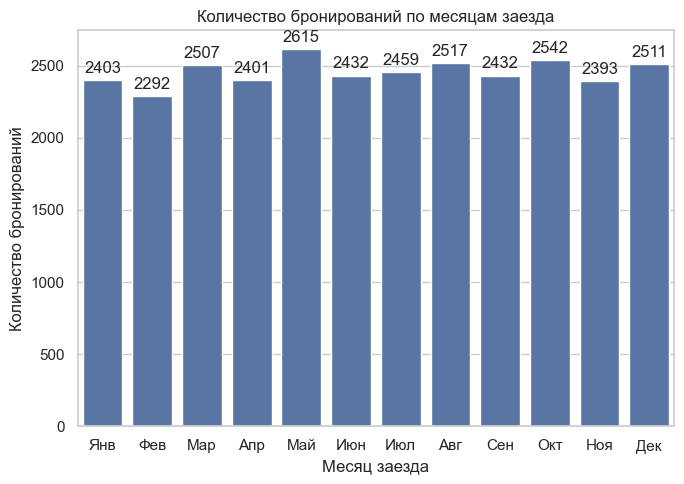

In [46]:
month_order = list(range(1, 13))

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df_booking_reviews,
    x='checkin_month',
    order=month_order,
    color='#4C72B0'
)

ax.set(
    title='Количество бронирований по месяцам заезда',
    xlabel='Месяц заезда',
    ylabel='Количество бронирований'
)

ax.set_xticklabels(
    ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
     'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
)

for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%d')
    
plt.tight_layout()
plt.show()

---
Группировка только по месяцам не выявила характерного рзаделения за сезонность

---

In [47]:
# Группируем данные по дате заезда
daily_counts = df_booking_reviews.groupby('planned_checkin').size().sort_index()

# Группируем данные по месяцам ('M') 
monthly_counts = df_booking_reviews.groupby(pd.Grouper(key='planned_checkin', freq='MS')).size().reset_index(name='booking_count')
#`` * freq='M' — конец месяца. * freq='MS' — начало месяца. * freq='W'` — по неделям.

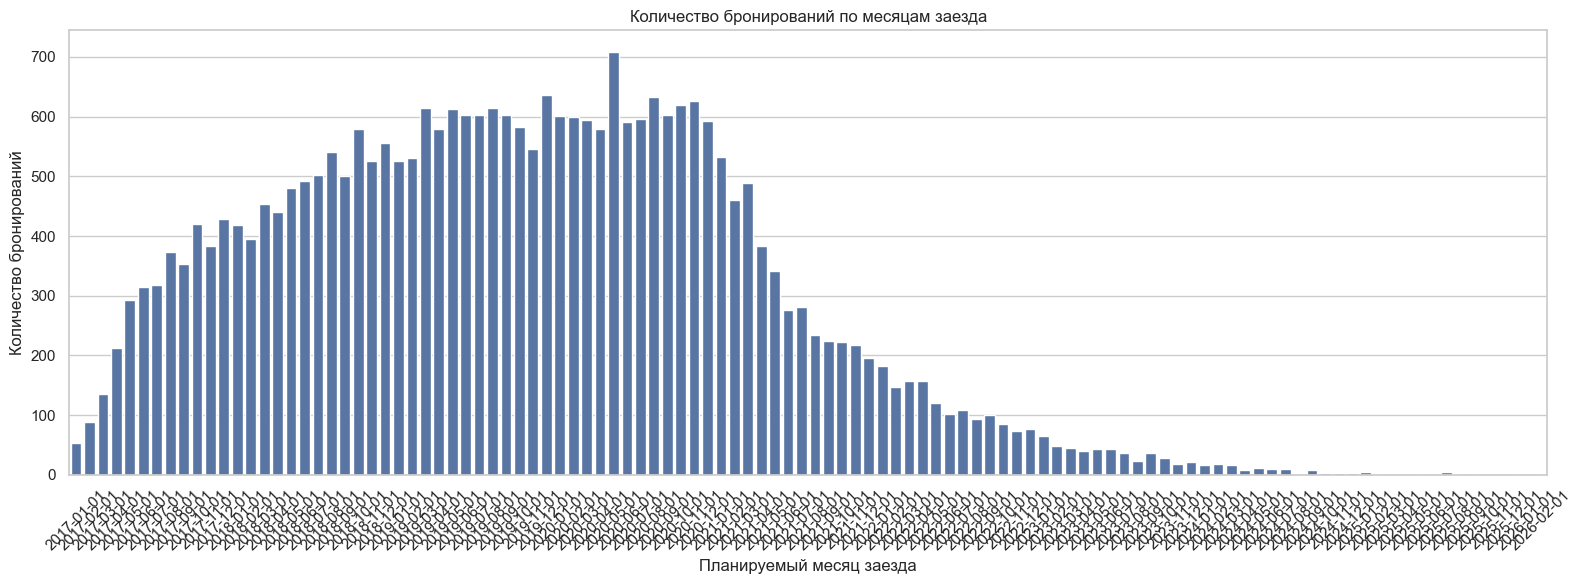

In [48]:
plt.figure(figsize=(16, 6))

ax = sns.barplot(
    data=monthly_counts,
    x='planned_checkin',
    y='booking_count',
    color='#4C72B0',
)

ax.set(
    title='Количество бронирований по месяцам заезда',
    xlabel='Планируемый месяц заезда',
    ylabel='Количество бронирований'
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
Данные сложно читаются, переоформим в линейный график 

---

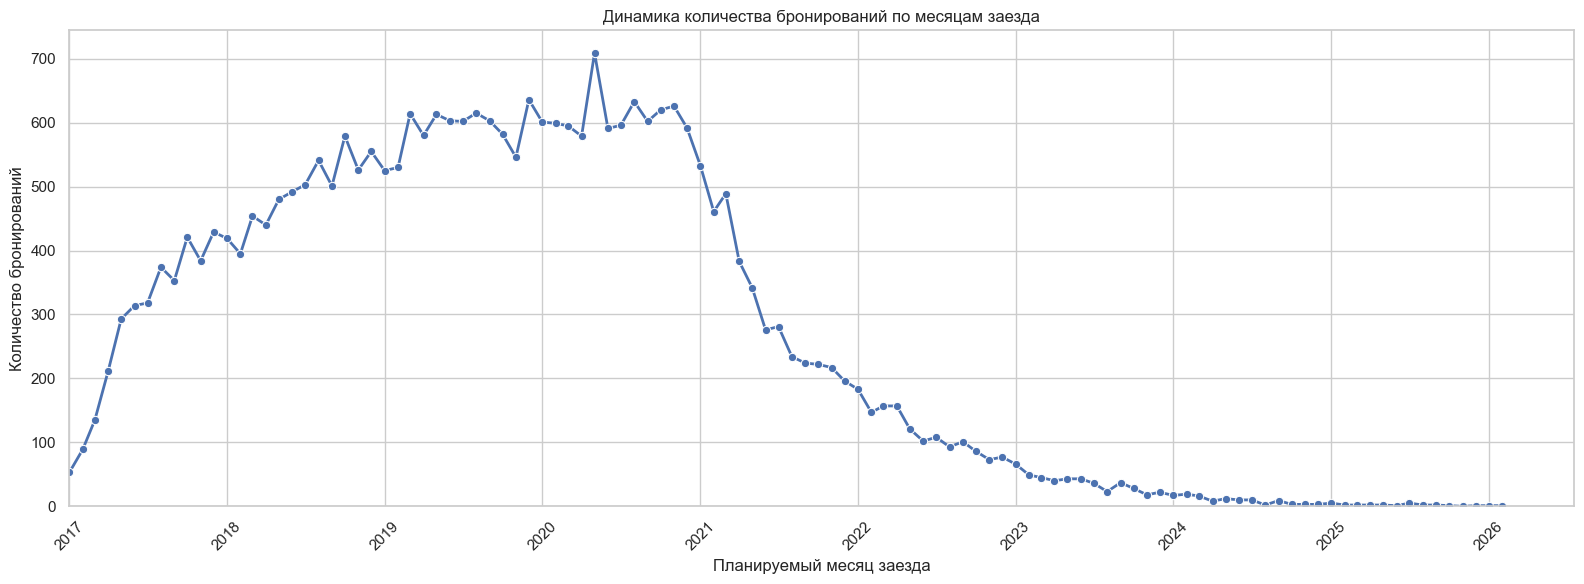

In [49]:
plt.figure(figsize=(16, 6))

ax = sns.lineplot(
    data=monthly_counts,
    x='planned_checkin',
    y='booking_count',
    marker='o',
    linewidth=2,
    color='#4C72B0'
)

ax.set(
    title='Динамика количества бронирований по месяцам заезда',
    xlabel='Планируемый месяц заезда',
    ylabel='Количество бронирований'
)
ax.set_ylim(bottom=0)
ax.set_xlim(
    left=monthly_counts['planned_checkin'].min()
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

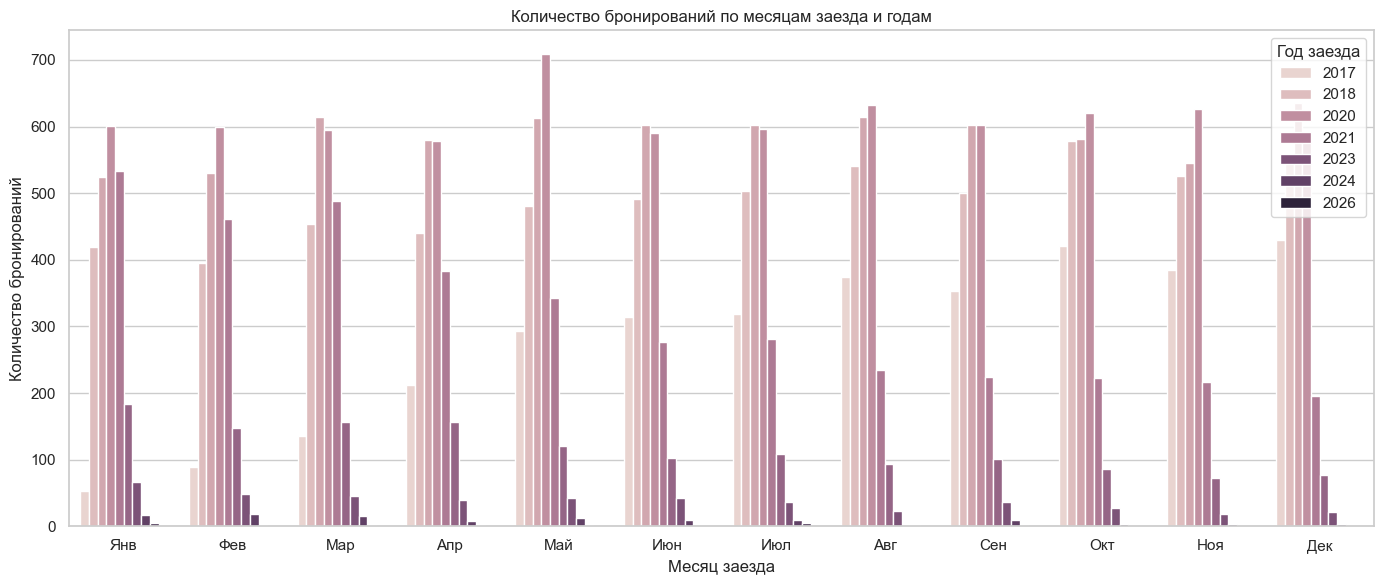

In [50]:
plt.figure(figsize=(14, 6))

ax = sns.countplot(
    data=df_booking_reviews,
    x='checkin_month',
    hue='checkin_year',
    order=month_order
)

ax.set(
    title='Количество бронирований по месяцам заезда и годам',
    xlabel='Месяц заезда',
    ylabel='Количество бронирований'
)

ax.set_xticklabels(
    ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
     'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
)

ax.legend(title='Год заезда')
plt.tight_layout()
plt.show()

---
**Вывод по сезонности заезда:**

- Количество бронирований по месяцам заезда меняется незначительно: от 2 394 до 2 714 записей, поэтому выраженная повторяющаяся сезонность по месяцам не выявлена.
- Основные различия наблюдаются между годами, а не между месяцами внутри года. Это указывает на временной тренд, а не на календарный сезонный эффект.
- В модель будет включён признак `checkin_month` и `day_of_week`.

In [51]:
df_booking_reviews = df_booking_reviews.drop(['checkin_year'], axis=1)

In [52]:
# второй признак: Лояльность клиента
# Сколько раз всего бронировал
df_booking_reviews['total_history'] = df_booking_reviews['previous_cancellations'] + df_booking_reviews['previous_no_shows']

# Анализ признака returning_customer
pd.crosstab(
    df_booking_reviews['returning_customer'],
    df_booking_reviews['total_history'].gt(0),
    margins=True
)

total_history,False,True,All
returning_customer,,,
False,11056,1798,12854
True,0,16650,16650
All,11056,18448,29504


---
Среди клиентов с `returning_customer = 0` у 1 873 записей (14,0%) также обнаружена история бронирований, т.е. признак показывает, что клиент уже заселялся в отель и бронирует еще раз.

Добавим еще один признак:
`has_booking_history` – показывает бронировал ли вообще (в том числе с учетом отмен):


In [53]:
# наличие истории бронирований
df_booking_reviews['has_booking_history'] = (
    df_booking_reviews['total_history'] > 0
).astype('int8')

# лояльность:
df_booking_reviews['loyalty_share'] = df_booking_reviews['previous_no_shows'] / df_booking_reviews['total_history'].replace(0, np.nan)
# заменим nan на -1, чтобы отличать клиента без истории
df_booking_reviews['loyalty_share'] = (
    df_booking_reviews['loyalty_share']
    .fillna(-1)
)
df_booking_reviews

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests,customer_id,stay_rating,review_text,planned_checkin,checkin_month,day_of_week,total_history,has_booking_history,loyalty_share
0,INN00000,2020-07-08,корпоративное_бронирование,3,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0,C0001,NaN,NaN,2020-07-29,7,2,0,0,-1.0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1,C0001,3.0,"Неплохо. тихо и спокойно, но отсутствие фена в...",2021-10-04,10,0,1,1,1.0
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,0,C0001,3.0,"Неплохо. красивое оформление территории, но не...",2023-02-23,2,3,2,1,1.0
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.0,150,6,2,тип_питания_1,False,тип_1,0,C0002,NaN,NaN,2017-07-11,7,1,0,0,-1.0
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,1,C0003,NaN,NaN,2019-06-10,6,0,2,1,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29499,INN30727,2020-03-05,корпоративное_бронирование,1,0,False,0,0,отказ_брони,89000.0,210,8,2,не выбран,False,тип_1,0,NaN,NaN,NaN,2020-10-01,10,3,0,0,-1.0
29500,INN30728,2020-04-08,корпоративное_бронирование,1,0,False,1,0,нет_отказа,13400.0,7,2,0,тип_питания_1,False,тип_1,2,C16473,NaN,NaN,2020-04-15,4,2,1,1,0.0
29501,INN30729,2017-01-31,корпоративное_бронирование,1,2,False,0,0,нет_отказа,6700.0,50,1,0,тип_питания_2,False,тип_1,1,C16474,NaN,NaN,2017-03-22,3,2,0,0,-1.0
29502,INN30730,2019-10-11,офлайн_бронирование,1,1,False,0,0,нет_отказа,53600.0,15,6,2,тип_питания_1,False,тип_1,1,C16475,NaN,NaN,2019-10-26,10,5,0,0,-1.0


In [54]:
# третий признак: ценовой уровень брони
# одна и та же сумма booking_value имеет разный смысл для одной ночи и для недельного проживания семьи
# введем признак всего ночей
df_booking_reviews['total_nights'] = df_booking_reviews['weekday_nights'] + df_booking_reviews['weekend_nights']

# ценовой уровень брони
df_booking_reviews['booking_value_per_night'] = df_booking_reviews['booking_value'] / df_booking_reviews['total_nights'].replace(0, np.nan)


#### Создайте новые признаки на основе текстов отзывов, используя один из методов векторизации. Решение о количестве таких признаков примите самостоятельно.
---

In [55]:
# Контраст между рейтингом и текстом отзыва
# Такое несоответствие может сигнализировать о неуверенности клиента — а неуверенные чаще отменяют.
# Получим числовое значение текста отзыва и сравнием его с числом рейтинга

# Загрзука датасета Rusentiment
file_name = 'sentiment_dataset.csv'
try:
    # Загрузка файла с диска
    df_rusentiment = pd.read_csv(Path('datasets') / file_name, sep=',', decimal='.')
except FileNotFoundError:
    print('проверьте наличие файлов')


display(df_rusentiment.head())
display(df_rusentiment['label'].unique())
display(df_rusentiment.info())

,text,label,src
0,"Пальто красивое, но пришло с дырой в молнии. П...",0,rureviews
1,"Очень долго шел заказ,ждала к новому году,приш...",0,rureviews
2,"Могу сказать одно, брюки нормальные, НО они бы...",0,rureviews
3,"Доставка быстрая, меньше месяца. Заказывали ра...",0,rureviews
4,Мне не очень понравилось это платье. Размер ...,0,rureviews


array([0, 1, 2])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290458 entries, 0 to 290457
Data columns (total 3 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    290458 non-null  object
 1   label   290458 non-null  int64 
 2   src     290458 non-null  object
dtypes: int64(1), object(2)
memory usage: 6.6+ MB


None

---
Набор данных содержит следующие столбцы:
- text: текст отзыва или комментария.
- label: метка тональности, где:
    - 0: нейтральная
    - 1: положительная
    - 2: отрицательная
- src: исходный набор данных.

---

In [56]:
df_rusentiment['label'].value_counts(normalize=True)

label
2    0.333928
1    0.333532
0    0.332540
Name: proportion, dtype: float64

In [57]:
# Базовая обработка текста: перевод в нижний регистр, удаление некириллических символов, токенизация
df_rusentiment['text'] = df_rusentiment['text'].str.lower()
df_rusentiment['text'] = df_rusentiment['text'].apply(lambda x: re.sub(r'[^а-яё\s]', '', x))
df_rusentiment['tokens'] = df_rusentiment['text'].apply(lambda x: x.split())

In [58]:
 # Определим перечень стоп-слов на русском языке
russian_stopwords = set(stopwords.words('russian'))

In [59]:
# Удаление стоп-слов из токенов 
df_rusentiment['tokens'] = df_rusentiment['tokens'].apply(
    lambda x: [word for word in x if word not in russian_stopwords]
)

In [60]:
# Разделим данные на обучающую и валидационную выборки для каждой модели
X_sent = df_rusentiment['text']
y_sent = df_rusentiment['label']
X_train_sent, X_test_sent, y_train_sent, y_test_sent = train_test_split(X_sent, y_sent, test_size=0.2, stratify=y_sent, random_state=RANDOM_STATE)

In [61]:
# сформируем пайплайн модели определения числовой вероятности тональности вектора
model_tfidf = TfidfVectorizer(
    stop_words=list(russian_stopwords),
    min_df=3,
    max_df=0.9,
    ngram_range=(1, 2), # используем биграммы
    max_features=20000
)
# Logreg для получения вероятности класса тональности
model_logreg = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

sentiment_model = Pipeline([
    ('tfidf', model_tfidf),
    ('model', model_logreg)
])

In [62]:
# обучаем модель на обучающей выборке
sentiment_model.fit(X_train_sent, y_train_sent)
# получаем предсказания по валидационным объектам
y_pred_sent = sentiment_model.predict(X_test_sent)

In [63]:
print('Accuracy:', round(accuracy_score(y_test_sent, y_pred_sent), 3))
print('F1 macro:', round(f1_score(y_test_sent, y_pred_sent, average='macro'), 3))

print('\nОтчёт по классам:')
print(
    classification_report(
        y_test_sent,
        y_pred_sent,
        target_names=['neutral', 'positive', 'negative']
    )
)

Accuracy: 0.683
F1 macro: 0.683

Отчёт по классам:
              precision    recall  f1-score   support

     neutral       0.58      0.59      0.58     19318
    positive       0.78      0.77      0.78     19375
    negative       0.70      0.68      0.69     19399

    accuracy                           0.68     58092
   macro avg       0.68      0.68      0.68     58092
weighted avg       0.68      0.68      0.68     58092



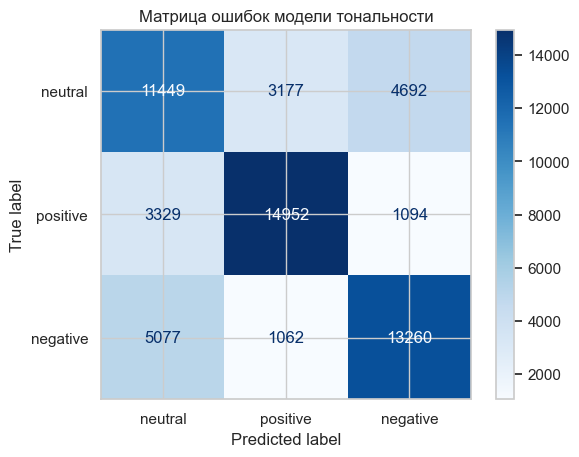

In [64]:
# построение матрицы ошибок

ConfusionMatrixDisplay.from_predictions(
    y_test_sent,
    y_pred_sent,
    display_labels=['neutral', 'positive', 'negative'],
    cmap='Blues'
)

plt.title('Матрица ошибок модели тональности')
plt.show()

In [65]:
# Проверка

# вывод сопоставления результата и факта
test_results = pd.DataFrame({
    'text': X_test_sent,
    'true_label': y_test_sent,
    'pred_label': y_pred_sent
})

test_results['is_correct'] = (
    test_results['true_label']
    == test_results['pred_label']
)

test_results.sample(10, random_state=RANDOM_STATE)

,text,true_label,pred_label,is_correct
67856,ужасная рубашка непонятно на какую фигуру сшит...,2,2,True
27976,доставка быстраякачество плохое кружева все в ...,0,0,True
221524,фильм имеет контраст который присущ большинств...,2,1,False
245982,вообще не тот вкус не та лапшатонкая и невкусн...,2,2,True
234956,заказ был отправлен быстро продавец прислал тр...,2,2,True
264444,по непонятной причине справляется с загрязнени...,0,2,False
254521,неудобно разливать большой расход,0,0,True
88215,мое мнение об этом аниме аниме стоящее для про...,0,2,False
96603,посмотрела за два дня соскучилась по жанру дет...,0,0,True
8376,не соответствует размер,0,0,True


In [66]:
test_results.query('is_correct == False').sample(10, random_state=RANDOM_STATE)

,text,true_label,pred_label,is_correct
90946,чувак бегает как джеки чан маст хэв да и чувс...,0,1,False
180957,грязный магазин без ремонта ужасное освещение ...,2,0,False
124572,мм не впечатлена сама по себе идея вернее даже...,2,0,False
11072,ну за такую цену возможно и ничего так но боль...,0,2,False
271122,для тех кто не понимает почему отзывы такие ра...,0,2,False
46111,тонкая тянучка по размеру шла месяц,1,0,False
204589,фильм сам по себе прекрасен всетаки это оливе...,0,1,False
52493,принт немного не пропечатан сзади на спине в о...,1,0,False
267412,безвкусная не понравилась,0,2,False
144125,среднего класса удобная транспортная развязка ...,0,1,False


In [67]:
# обучение модели на полном датасете
sentiment_model.fit(X_sent, y_sent)

review_text = df_booking_reviews['review_text'].fillna('')

sentiment_proba = sentiment_model.predict_proba(review_text)

# сведем вероятности тональности для каждого отзыва
sentiment_proba_df = pd.DataFrame(
    sentiment_proba,
    columns=sentiment_model.classes_,
    index=df_booking_reviews.index
)

sentiment_proba_df.head()

,0,1,2
0,0.430221,0.269667,0.300113
1,0.649929,0.241221,0.108850
2,0.310196,0.670150,0.019654
3,0.430221,0.269667,0.300113
4,0.430221,0.269667,0.300113


In [68]:
# создадим столбец есть отзыв или нет
# маска для пустого или отсутствующего отзыва
texts = df_booking_reviews['review_text'].fillna('').str.strip()
has_text = texts.ne('')

# столбец есть отзыв или нет
df_booking_reviews['has_review_text'] = has_text.astype('int8')
# столбец тональности
df_booking_reviews['sentiment_score'] = np.nan

In [69]:
# получим числовое значение тональности
sentiment_score = 3 * sentiment_proba_df[0] + 5 * sentiment_proba_df[1] + 1 * sentiment_proba_df[2]
df_booking_reviews['sentiment_score'] = sentiment_score

# столбец с разницей между рейтингом и тональностью отзыва
df_booking_reviews['rating_sentiment_gap'] = np.abs(df_booking_reviews['stay_rating'] - sentiment_score)

In [70]:
df_booking_reviews.head()

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests,customer_id,stay_rating,review_text,planned_checkin,checkin_month,day_of_week,total_history,has_booking_history,loyalty_share,total_nights,booking_value_per_night,has_review_text,sentiment_score,rating_sentiment_gap
0,INN00000,2020-07-08,корпоративное_бронирование,3,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0,C0001,NaN,NaN,2020-07-29,7,2,0,0,-1.0,1,6700.0,0,2.939107,NaN
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1,C0001,3.0,"Неплохо. тихо и спокойно, но отсутствие фена в...",2021-10-04,10,0,1,1,1.0,7,8900.0,1,3.264741,0.264741
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,0,C0001,3.0,"Неплохо. красивое оформление территории, но не...",2023-02-23,2,3,2,1,1.0,7,6700.0,1,4.300993,1.300993
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.0,150,6,2,тип_питания_1,False,тип_1,0,C0002,NaN,NaN,2017-07-11,7,1,0,0,-1.0,8,6700.0,0,2.939107,NaN
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,1,C0003,NaN,NaN,2019-06-10,6,0,2,1,0.5,7,6700.0,0,2.939107,NaN


- Сделать выводы о созданных признаках.
- ----

**Вывод по созданию признаков:**

- Рассчитаны планируемая дата заезда (`planned_checkin`), месяц (`checkin_month`) и день недели заезда (`day_of_week`). Устойчивая месячная сезонность не выявлена, поэтому бинарный признак высокого/низкого сезона не добавлен.
- Созданы признаки истории клиента и параметров проживания: число прошлых бронирований (`total_history`), доля бронирований, завершившихся заселением (`loyalty_share`), длительность проживания (`total_nights`) и стоимость брони за ночь (`booking_value_per_night`).
- Добавлены признаки наличия текста предыдущего отзыва (`has_review_text`), его тональности (`sentiment_score`) и расхождения тональности с оценкой клиента (`rating_sentiment_gap`).

### Анализ итоговой таблицы

- Проанализируйте итоговую таблицу.

- Сделайте выводы о данных для моделирования.

In [71]:
target = 'booking_status'

#### Full EDA

Размер датасета: (29504, 31)
Информация по датасету:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 31 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   booking_id                 29504 non-null  object        
 1   booking_date               29504 non-null  datetime64[ns]
 2   sales_channel              29504 non-null  object        
 3   adult_count                29504 non-null  int64         
 4   child_count                29504 non-null  int64         
 5   returning_customer         29504 non-null  bool          
 6   previous_cancellations     29504 non-null  int64         
 7   previous_no_shows          29504 non-null  int64         
 8   booking_status             29504 non-null  object        
 9   booking_value              29504 non-null  float64       
 10  days_until_checkin         29504 non-null  int64         
 11  weekday_nights

None


Первые строки:


,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests,customer_id,stay_rating,review_text,planned_checkin,checkin_month,day_of_week,total_history,has_booking_history,loyalty_share,total_nights,booking_value_per_night,has_review_text,sentiment_score,rating_sentiment_gap
0,INN00000,2020-07-08,корпоративное_бронирование,3,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0,C0001,NaN,NaN,2020-07-29,7,2,0,0,-1.0,1,6700.0,0,2.939107,NaN
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1,C0001,3.0,"Неплохо. тихо и спокойно, но отсутствие фена в...",2021-10-04,10,0,1,1,1.0,7,8900.0,1,3.264741,0.264741
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,0,C0001,3.0,"Неплохо. красивое оформление территории, но не...",2023-02-23,2,3,2,1,1.0,7,6700.0,1,4.300993,1.300993
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.0,150,6,2,тип_питания_1,False,тип_1,0,C0002,NaN,NaN,2017-07-11,7,1,0,0,-1.0,8,6700.0,0,2.939107,NaN
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,1,C0003,NaN,NaN,2019-06-10,6,0,2,1,0.5,7,6700.0,0,2.939107,NaN


##### Сводка по колонкам

,dtype,n_unique,n_missing,missing_%
stay_rating,float64,5,21483,72.81
rating_sentiment_gap,float64,5902,21483,72.81
review_text,object,5925,21483,72.81
customer_id,object,13082,8492,28.78
returning_customer,bool,2,0,0.00
booking_status,object,2,0,0.00
parking_included,bool,2,0,0.00
has_booking_history,int8,2,0,0.00
has_review_text,int8,2,0,0.00
sales_channel,object,3,0,0.00


Число дубликатов: 0
Константные колонки: Нет


##### Группы признаков

Числовые: ['booking_value', 'days_until_checkin', 'weekday_nights', 'loyalty_share', 'total_nights', 'booking_value_per_night', 'sentiment_score', 'rating_sentiment_gap']
Категориальные: ['sales_channel', 'returning_customer', 'meal_plan', 'parking_included', 'room_type', 'review_text', 'adult_count', 'child_count', 'previous_cancellations', 'previous_no_shows', 'weekend_nights', 'customer_special_requests', 'stay_rating', 'checkin_month', 'day_of_week', 'total_history', 'has_booking_history', 'has_review_text']
Datetime: ['booking_date', 'planned_checkin']


##### Пропуски

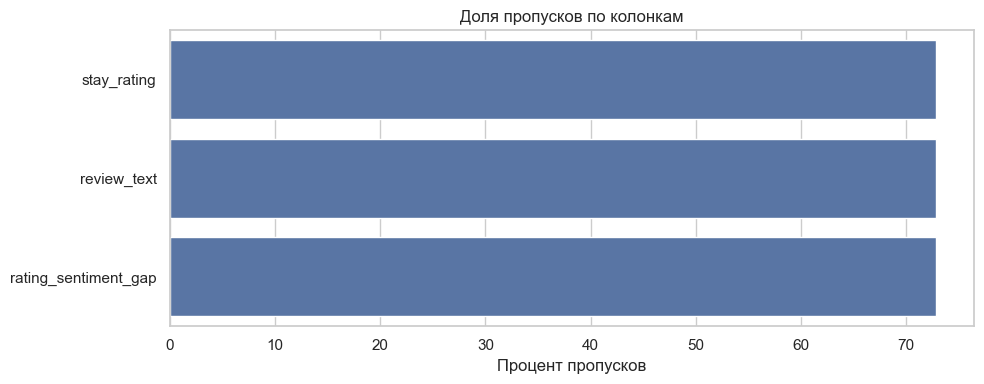

##### Числовые признаки

,count,mean,std,min,25%,50%,75%,max
booking_value,29504.0,64248.436849,41683.137007,6700.000000,46900.000000,60300.000000,89000.000000,417221.200000
days_until_checkin,29504.0,100.541994,71.926833,2.000000,45.000000,90.000000,144.000000,300.000000
weekday_nights,29504.0,6.534063,3.338803,1.000000,5.000000,6.000000,9.000000,15.000000
loyalty_share,29504.0,0.083354,0.878931,-1.000000,-1.000000,0.500000,1.000000,1.000000
total_nights,29504.0,8.487561,4.723768,1.000000,5.000000,8.000000,11.000000,21.000000
booking_value_per_night,29504.0,7564.290504,2167.888292,6700.000000,6700.000000,6700.000000,6700.000000,19995.350000
sentiment_score,29504.0,3.183450,0.632490,1.102274,2.939107,2.939107,2.939107,4.996296
rating_sentiment_gap,8021.0,0.566433,0.369082,0.000015,0.204349,0.625078,0.883873,1.921325


Оценка выбросов по правилу IQR


,outliers_count,outliers_%
sentiment_score,8021,27.19
booking_value_per_night,6695,22.69
total_nights,910,3.08
booking_value,732,2.48
days_until_checkin,327,1.11
rating_sentiment_gap,2,0.01
loyalty_share,0,0.00
weekday_nights,0,0.00


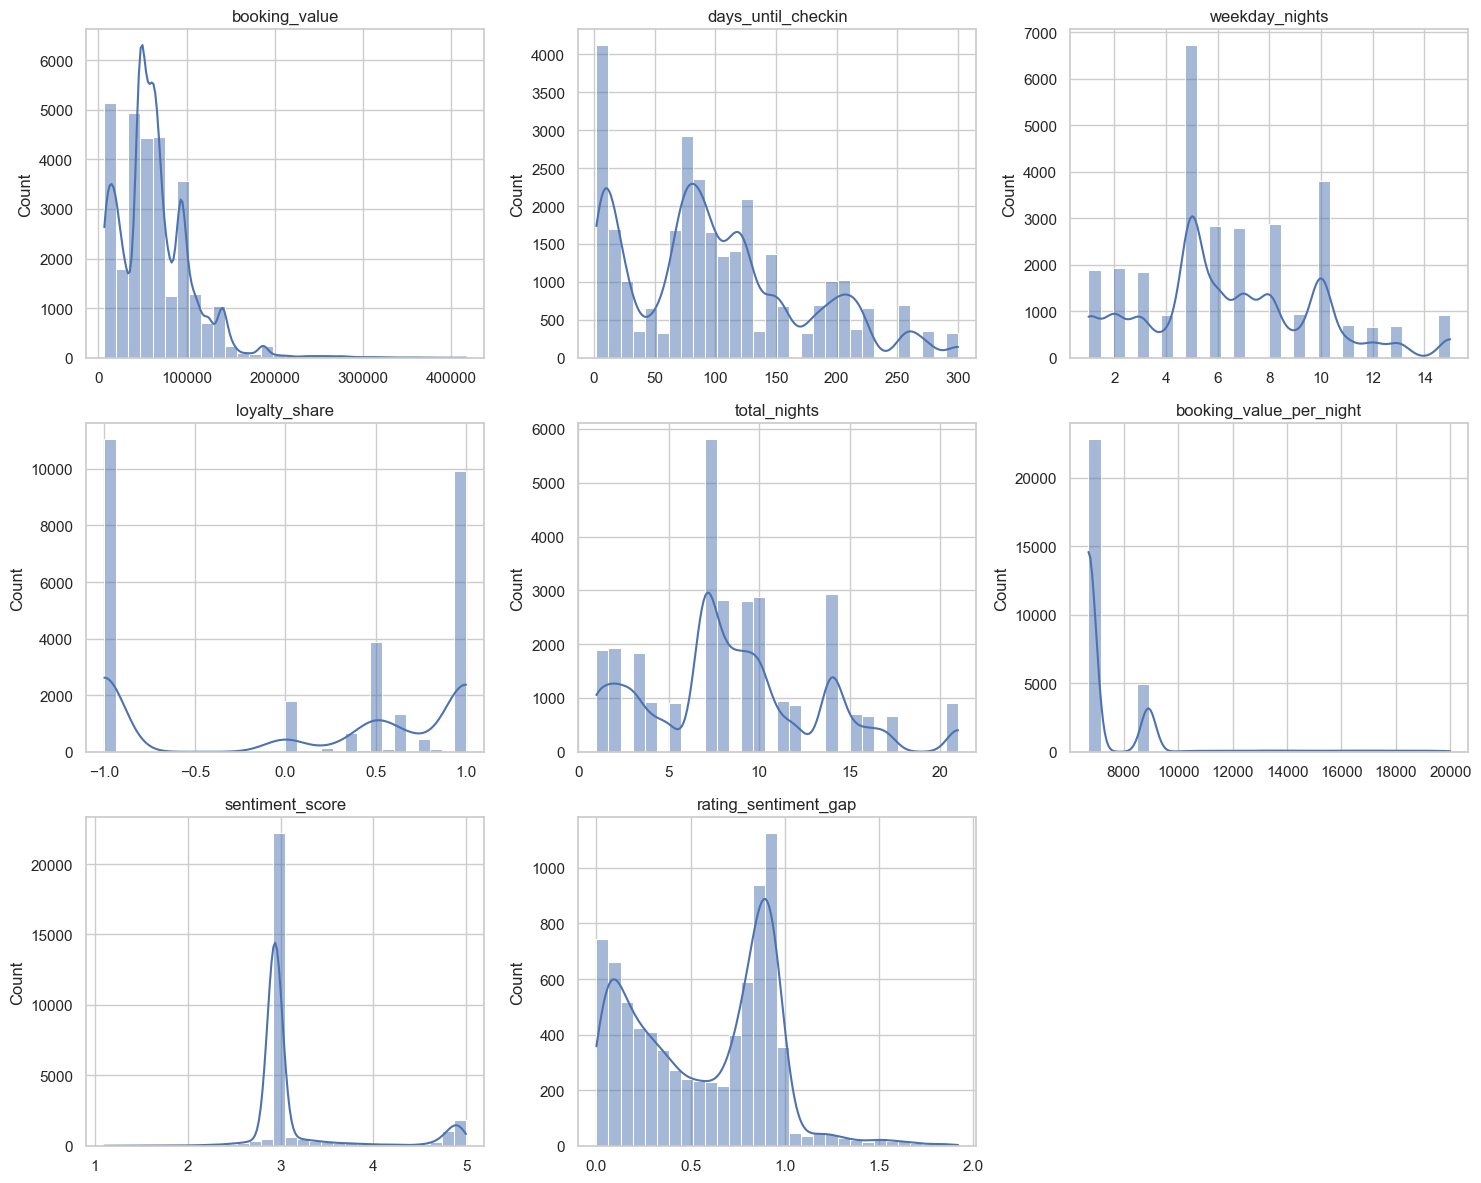

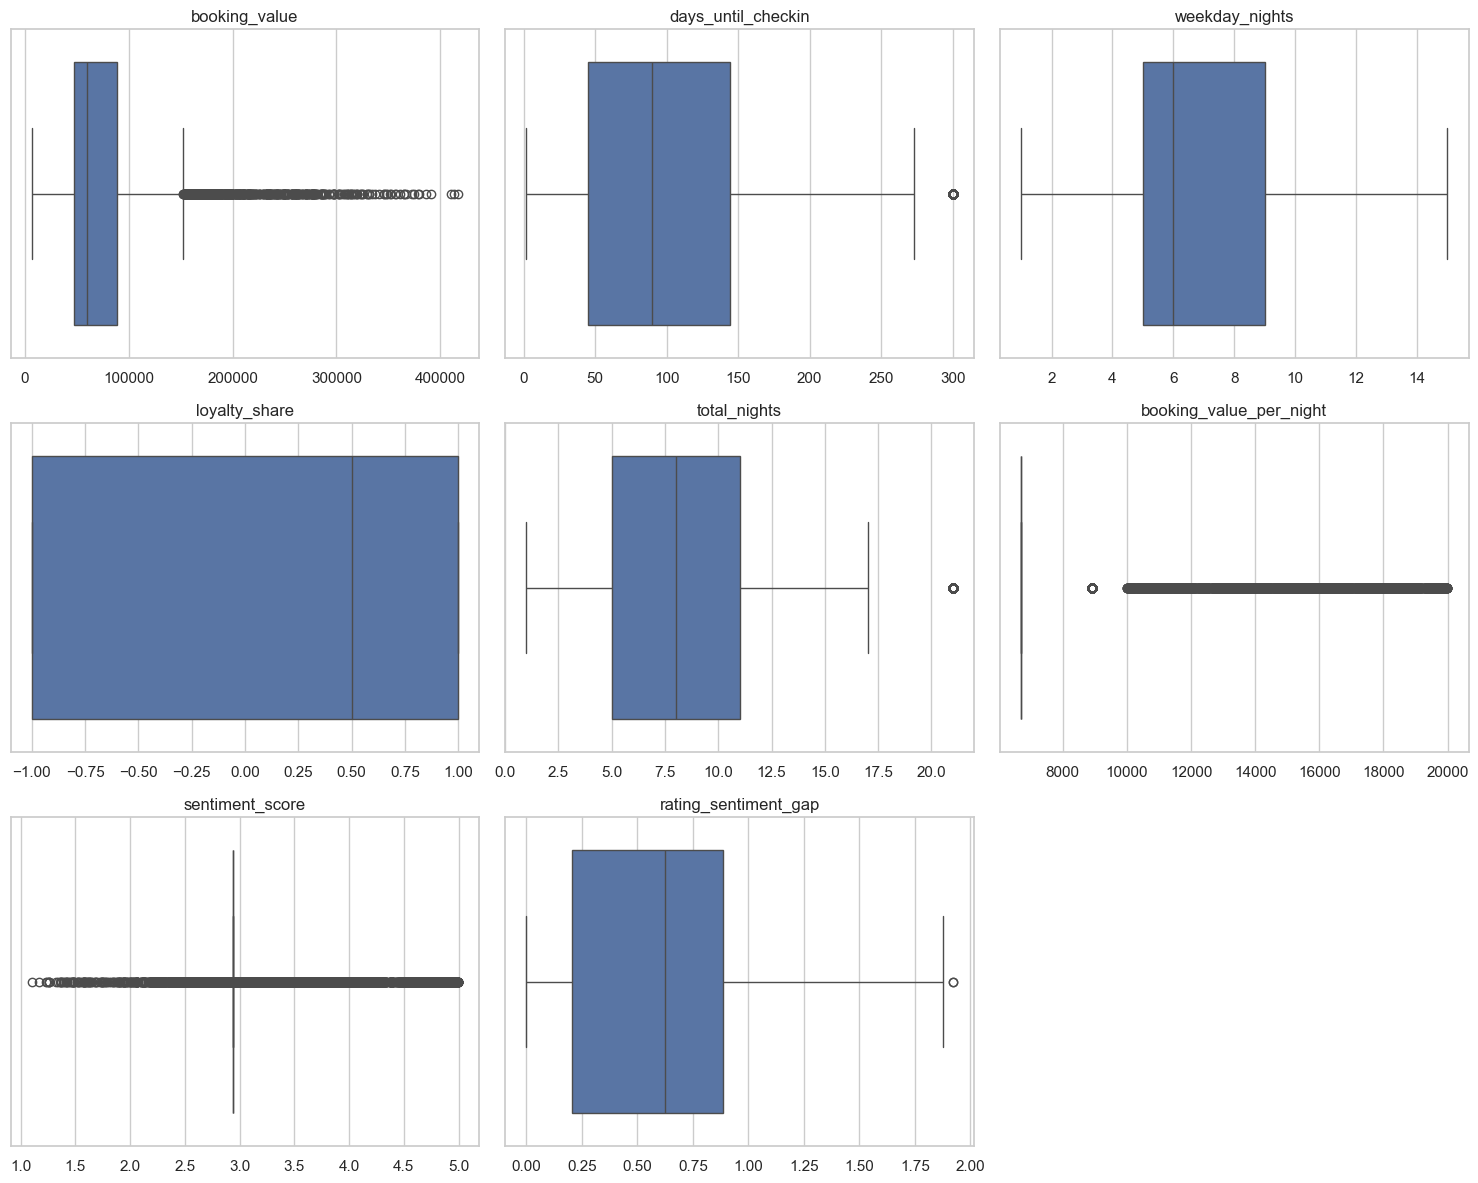

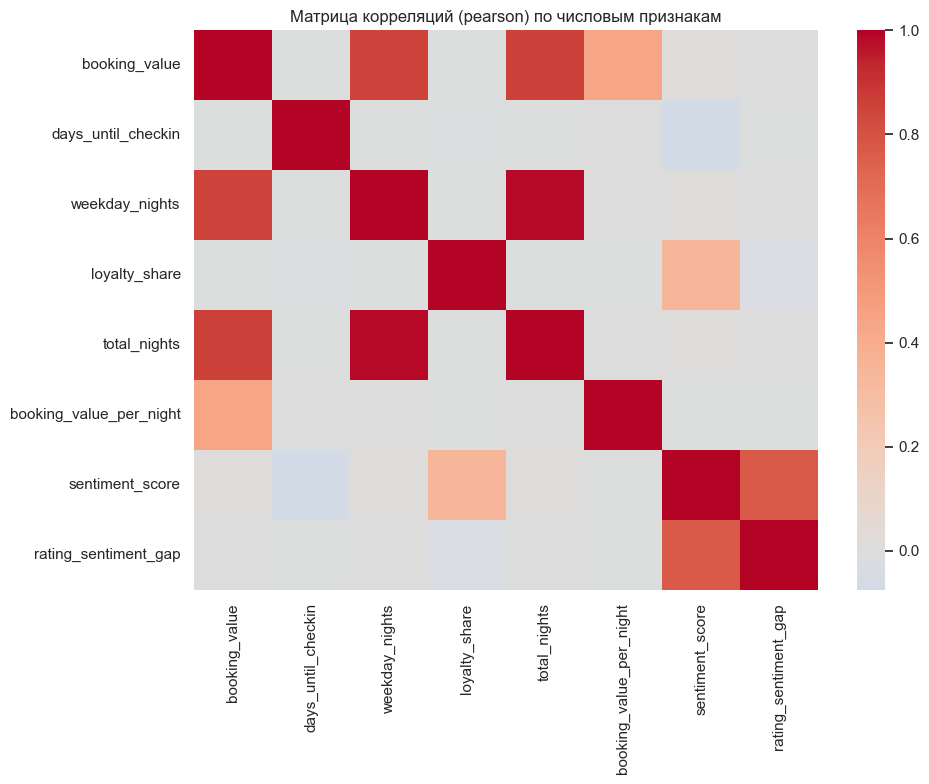

##### Категориальные признаки

,n_unique,missing_%,top_values
returning_customer,2,0.00,"True, False"
parking_included,2,0.00,"False, True"
has_booking_history,2,0.00,"1, 0"
has_review_text,2,0.00,"0, 1"
sales_channel,3,0.00,"офлайн_бронирование, корпоративное_бронировани..."
adult_count,3,0.00,"1, 2, 3"
child_count,3,0.00,"0, 1, 2"
meal_plan,4,0.00,"тип_питания_1, не выбран, тип_питания_2"
weekend_nights,4,0.00,"2, 0, 4"
stay_rating,5,72.81,"<NA>, 3.0, 4.0"


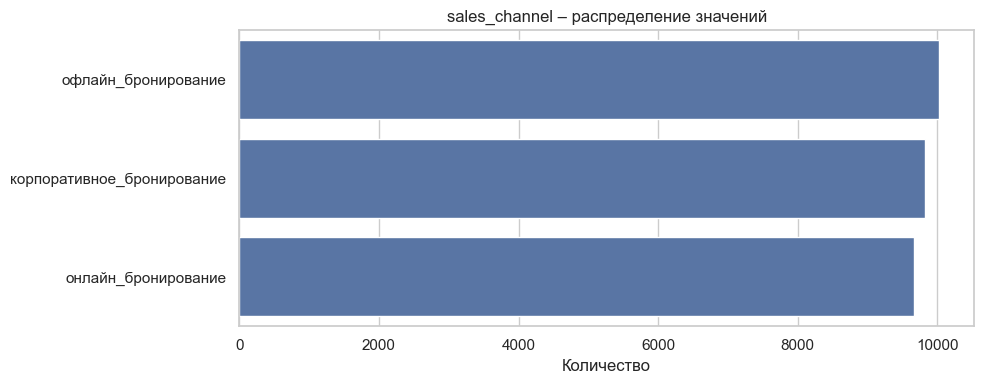

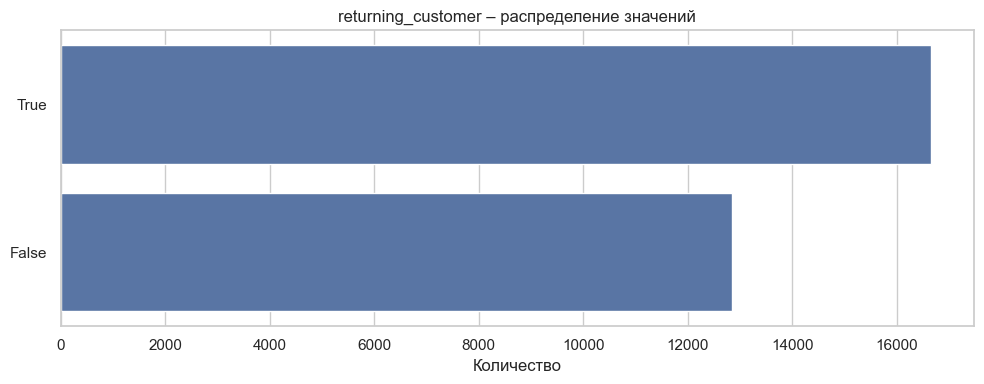

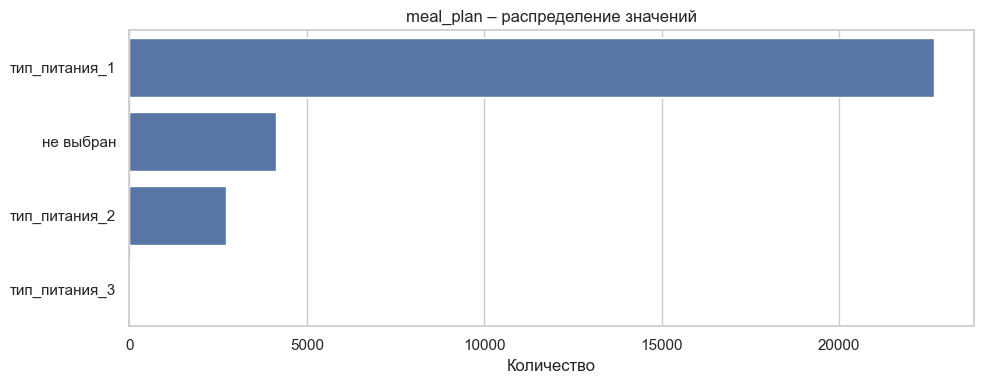

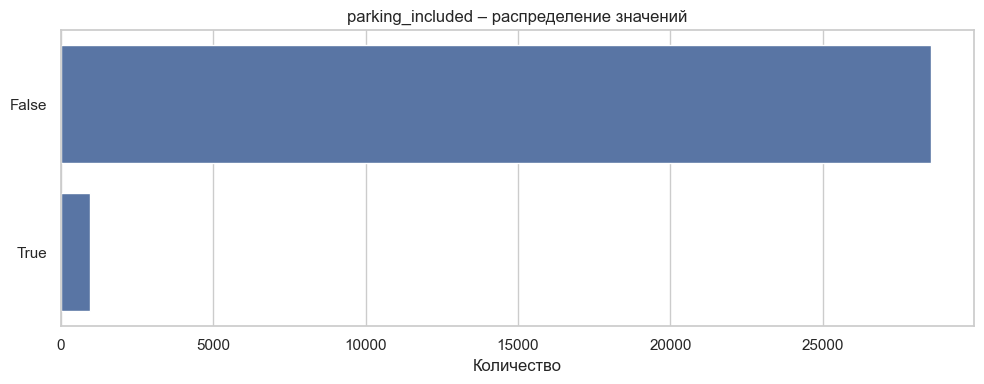

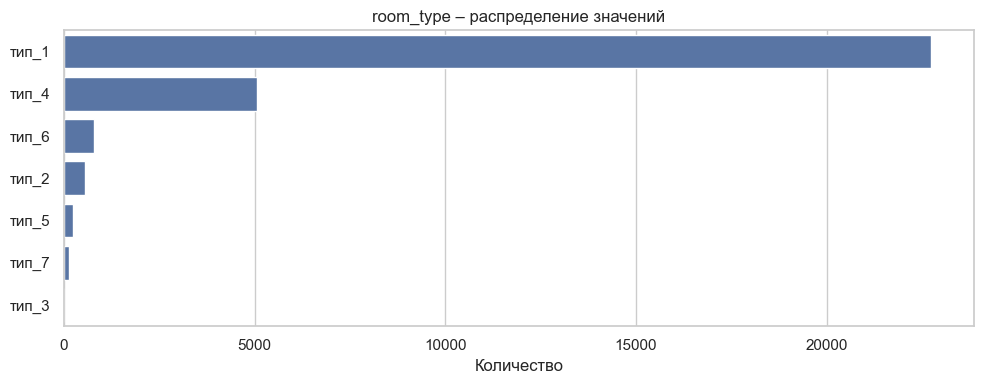

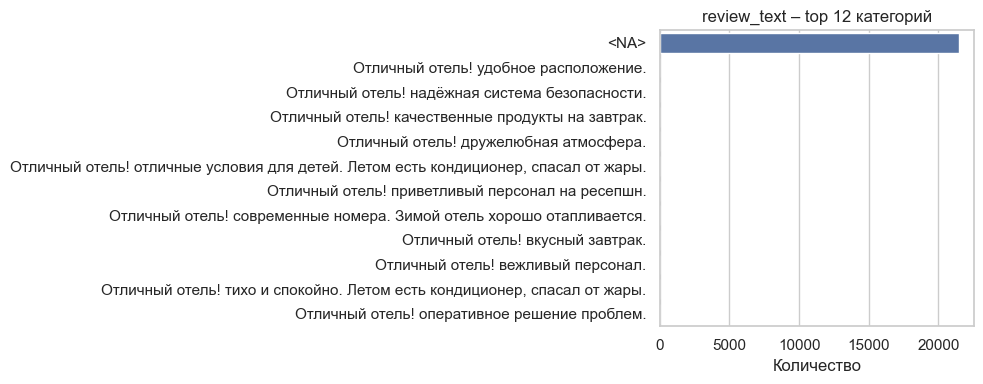

##### Datetime-признаки

,min,max,missing_%
booking_date,2017-01-01,2025-10-22,0.0
planned_checkin,2017-01-06,2026-02-06,0.0


interval columns not set, guessing: ['adult_count', 'child_count', 'previous_cancellations', 'previous_no_shows', 'booking_value', 'days_until_checkin', 'weekday_nights', 'weekend_nights', 'customer_special_requests', 'stay_rating', 'checkin_month', 'day_of_week', 'total_history', 'has_booking_history', 'loyalty_share', 'total_nights', 'booking_value_per_night', 'has_review_text', 'sentiment_score', 'rating_sentiment_gap']


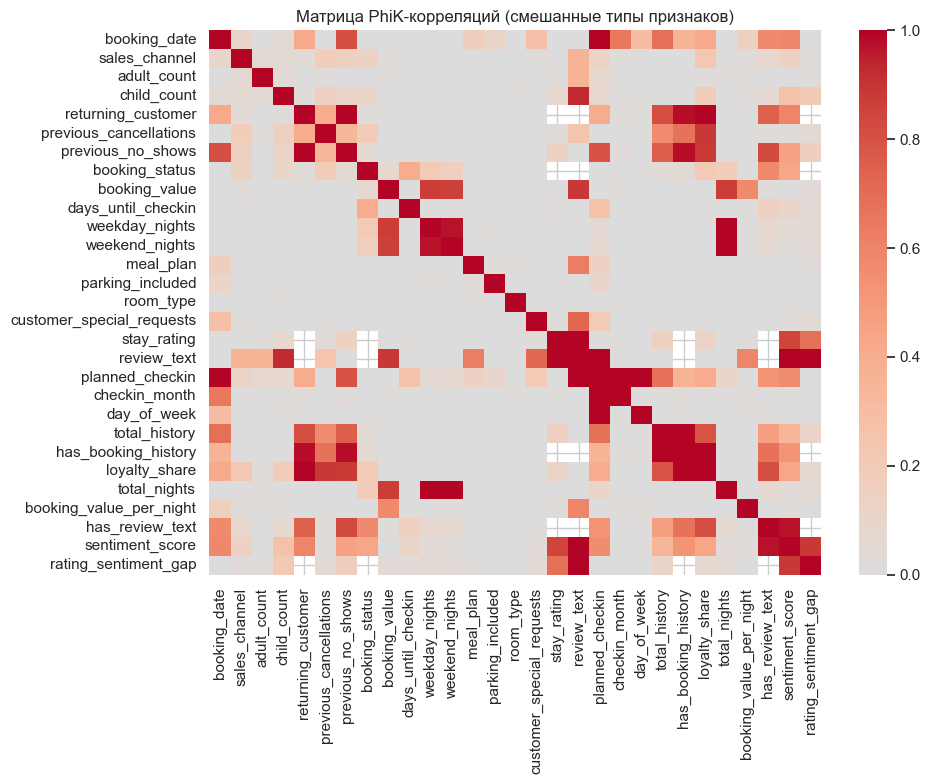

##### Target

###### Анализ target: `booking_status`

booking_status
нет_отказа     21012
отказ_брони     8492
Name: count, dtype: int64

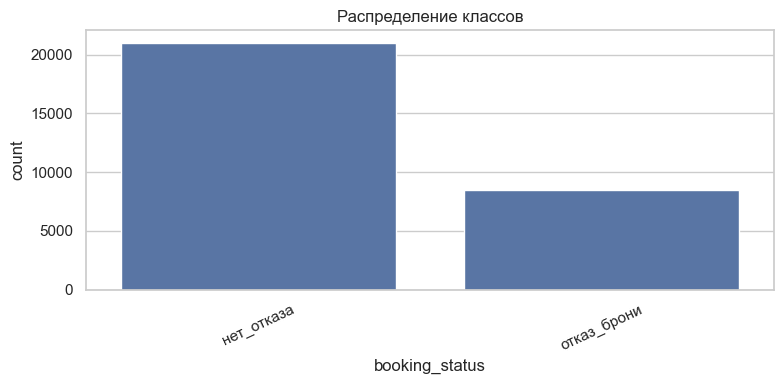

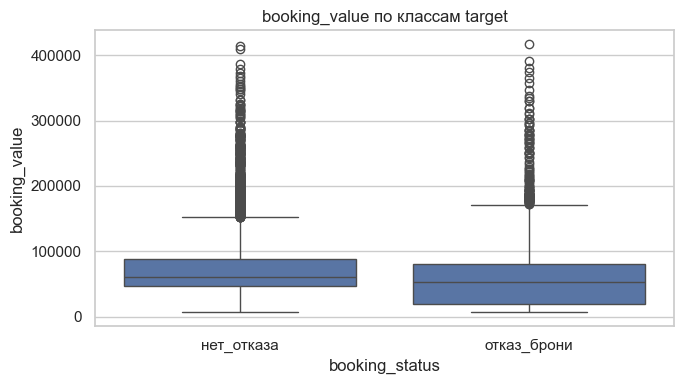

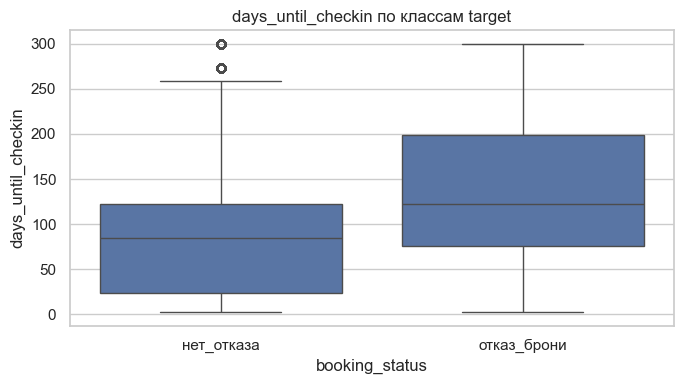

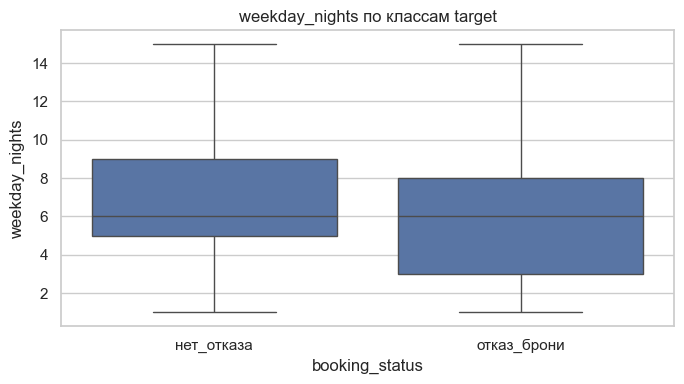

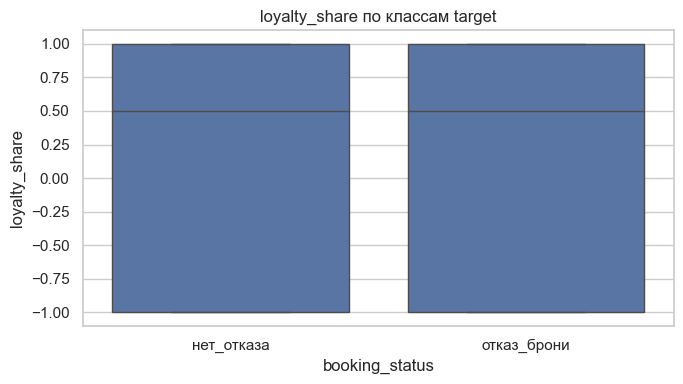

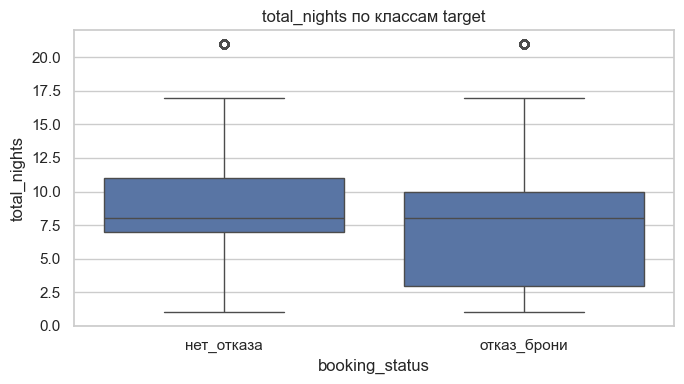

###### Связь признаков с target

Target не является числовым: стандартная корреляция Пирсона/Спирмена пропущена.


###### PhiK: связь признаков с target

interval columns not set, guessing: ['adult_count', 'child_count', 'previous_cancellations', 'previous_no_shows', 'booking_value', 'days_until_checkin', 'weekday_nights', 'weekend_nights', 'customer_special_requests', 'stay_rating', 'checkin_month', 'day_of_week', 'total_history', 'has_booking_history', 'loyalty_share', 'total_nights', 'booking_value_per_night', 'has_review_text', 'sentiment_score', 'rating_sentiment_gap']


KeyboardInterrupt: 

In [73]:
eda_template.full_eda(df_booking_reviews, exclude_cols=['booking_id', 'customer_id'], target=target, task='classification')

**Вывод по итоговой таблице:**
1. Итоговый датасет состоит из 30 колонок и 30733 строк.
2. Колонки `booking_id`, `customer_id` являются техническими, `booking_date`, `planned_checkin` - имеют тип дата на их основе получены другие столбцыб `review_text` – текстовый столбец на его основе также получены другие столбцы . С учетом сказанного данные столбцы не будут исопльзоваться при моделировании.
3. Дубликаты в данных отсутствуют.
4. Пропуски встречаются только в столбцах связанных с оценками бранирования пользователей, т.к. их гораздо меньше чем всего бронирований. В дальнейшем пропску будут обработаны – заменены на константы с сохранением флагов пропусков. Тем самым индикаторы позволяют модели учитывать отсутствие информации после заполнения.
5. Выявлены выбросы у признаков соответсвуют физическим и бизнес параметрам признаков.
6. Анализ корреляции признаков между собой показал следующее:
    - Сильная связь наблюдается между длительностью проживания (`total_nights`) и количеством будних и выходных ночей, а также между признаками истории клиента: `returning_customer`, `previous_no_shows`, `total_history`, `has_booking_history` и `loyalty_share`. Часть этой связи обусловлена формулами создания новых признаков.
    - Календарные признаки связаны с датами бронирования и планируемого заезда. Также заметна связь стоимости брони (`booking_value`) с длительностью проживания и стоимостью за ночь.
7. Распределение целевой переменной составляет:
    - "нет_отказа" – 21012
    - "отказ_брони" – 8492.
8. Соотношение примерно 2.47:1 – есть выраженный дисбаланс.
9. При обучении модели следует использовать метрики, чувствительные к редкому классу, и методы компенсации дисбаланса
10. Анализ корреляции признаков с целевой переменной:
    - Наибольшую связь с `booking_status` показывают наличие текста предыдущего отзыва (`has_review_text`, PhiK = 0.572), его тональность (`sentiment_score`, 0.437) и срок до заезда (`days_until_checkin`, 0.400).
    - Менее выраженная связь наблюдается у лояльности клиента (`loyalty_share`, 0.207), числа будних ночей (`weekday_nights`, 0.200), предыдущих отмен (`previous_cancellations`, 0.196) и общей длительности проживания (`total_nights`, 0.187).
    - Наименьшую связь среди рассмотренных признаков имеет стоимость за ночь (`booking_value_per_night`, 0.016).

## Этап 2: моделирование

### Обучение и оптимизация модели

- Выберите и обучите не менее двух моделей из списка:

  - Random Forest;

  - CatBoost;

  - LightGBM;

  - XGBoost;

  - любую другую на ваш выбор.

- Разделите данные на три выборки:
  - Обучающую — для обучения моделей (60% данных);
  - Калибровочную — для проведения калибровки модели (20% данных);
  - Тестовую — для финальной оценки качества выбранной модели (20% данных).

- Проведите кросс-валидацию, используйте три фолда. Размер выборки для валидации — 2000.

- Оптимизируйте гиперпараметры с помощью Optuna. Количество гиперпараметров — не менее трёх. Ключевая метрика для оптимизации — Incremental Revenue.

- Сделайте выводы о том, какая модель показала лучшие результаты.

---
Перед моделированием изменим значения у целевой переменной. Назначим:

    0 — нет_отказа;
    1 — отказ_брони: событие, которое прогнозируем.

In [77]:
target_mapping = {
    'нет_отказа': 0,
    'отказ_брони': 1
}

df_booking_reviews['target'] = df_booking_reviews['booking_status'].map(target_mapping)
target = 'target'
# Проверяем, что все значения распознаны
# провекра по распределению
print(df_booking_reviews['target'].value_counts())

target
0    21012
1     8492
Name: count, dtype: int64


In [78]:
# определение границ выборок
total = len(df_booking_reviews) 
train_size = int(0.60 * total) 
remaining = total - train_size

# отсортируем данные по времени букинга, чтобы не было утечек
df_booking_reviews = df_booking_reviews.sort_values('booking_date')

# разделение на выборки
df_train = df_booking_reviews.iloc[:train_size].reset_index(drop=True).copy()
df_calib = df_booking_reviews.iloc[train_size:int(train_size + remaining / 2)].reset_index(drop=True).copy()
df_test = df_booking_reviews.iloc[int(train_size + remaining / 2):].reset_index(drop=True).copy()

for name, selection in [('train', df_train), ('calib', df_calib), ('test', df_test)]:
    print(f'\n{name} size: {selection.shape[0]}')
    print(f'Баланс в {name}:')
    print(selection[target].value_counts(normalize=True))

    date_min=selection['booking_date'].min().date()
    date_max=selection['booking_date'].max().date()
    print(f'Начало периода {date_min}')
    print(f'Конец периода {date_max}')
    print('*' * 35)


train size: 17702
Баланс в train:
target
0    0.704045
1    0.295955
Name: proportion, dtype: float64
Начало периода 2017-01-01
Конец периода 2019-12-01
***********************************

calib size: 5901
Баланс в calib:
target
0    0.704626
1    0.295374
Name: proportion, dtype: float64
Начало периода 2019-12-01
Конец периода 2020-09-20
***********************************

test size: 5901
Баланс в test:
target
0    0.744111
1    0.255889
Name: proportion, dtype: float64
Начало периода 2020-09-20
Конец периода 2025-10-22
***********************************


In [79]:
drop_cols = ['booking_id', 'booking_date', 'booking_status', 'customer_id', 'review_text', 'planned_checkin', 'target']
feature_cols = [col for col in df_booking_reviews.columns if col not in drop_cols]

# формирование выборок
X_train = df_train[feature_cols]
y_train = df_train[target]
X_calib = df_calib[feature_cols]
y_calib = df_calib[target]
X_test = df_test[feature_cols]
y_test = df_test[target]

In [104]:
# Категориальные признаки
# приведение столбцов к категориальному виду
cat_features = ['sales_channel', 'meal_plan', 'room_type']

for col in cat_features:
    X_train[col] = X_train[col].astype('category')
    X_calib[col] = X_calib[col].astype('category')
    X_test[col] = X_test[col].astype('category')

# числовые признаки
num_features = X_train[feature_cols].select_dtypes(
    include=np.number
).columns.tolist()

num_features_rew = ['stay_rating', 'sentiment_score', 'rating_sentiment_gap']
num_features_ready = [col for col in num_features if col not in num_features_rew]

# булевые признаки
bool_features = X_train[feature_cols].select_dtypes(
    include=['bool']
).columns.tolist()

# Преобразования числовых столбцов:
# пропуски в 'stay_rating' и 'rating_sentiment_gap' заменим на -1
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant',
                              fill_value=-1,
                              add_indicator=True ))
])

# Преобразования категориального столбца:
# most_frequent — замена возможных пропусков;
# OneHotEncoder — создание отдельных колонок для каждого статуса.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

# препроцессоры
preprocessor_lgbm = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_features_rew),
        ('ready_num', 'passthrough', num_features_ready),
        ('cat', 'passthrough', cat_features),
        ('bool', 'passthrough', bool_features),
    ],
    remainder='drop',
    verbose_feature_names_out=False # убирает префиксы num__, cat__ и другие из названий признаков.
).set_output(transform='pandas') # сохраняет табличный формат на выходе преобразований.

preprocessor_rf = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_features_rew),
        ('ready_num', 'passthrough', num_features_ready),
        ('cat', categorical_transformer, cat_features),
        ('bool', 'passthrough', bool_features),
    ],
    remainder='drop'
)

In [105]:
# Сформируем 2 модели
# Параметр class_weight='balanced' автоматически задаёт веса классов обратно пропорционально их частотам

model_lgbm = LGBMClassifier(
    class_weight='balanced',
    verbosity=0,
    random_state=RANDOM_STATE,
    categorical_feature=cat_features
)

model_rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=1,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=-1
)

# Пайплайн с базовой моделью LGBMClassifier
pipeline_lgbm = Pipeline([
    ('preprocessor', preprocessor_lgbm),
    ('model', model_lgbm)
])

# Пайплайн с базовой моделью RandomForest
pipeline_rf = Pipeline([
    ('preprocessor', preprocessor_rf),
    ('model', model_rf)
])

In [90]:
# функция Incremental Revenue
def ir_function(y_true, TN, FP, FN, TP):
    # Бизнес-константы
    AVG_REV = 64500       # Средний доход с одной успешной брони (руб.)
    COST_FP = 7000        # Стоимость ложного срабатывания (компенсация, лояльность) 
    LOST_REV = 64500      # Упущенный доход при отмене (обычно равен AVG_REV)
    PER_REBOOKING = 45000  # Доход от повторной сдачи номера (может быть чуть меньше из-за скидки)

    total_success = (y_true == 0).sum() # все успешные брони
    total_cancellations = (y_true == 1).sum() # все отмены бронирования.

    # Доход до внедрения модели
    ir_before = total_success * AVG_REV - total_cancellations * LOST_REV 
    # Доход после внедрения модели
    ir_after = TP * PER_REBOOKING + TN * AVG_REV - FP * COST_FP - FN * LOST_REV

    # Расчёт IR
    ir  = ir_after - ir_before
    # Относительный IR
    ir_relat = (ir_after - ir_before) / ir_before * 100
    
    return ir, ir_relat

In [91]:
# Функция расчёта метрик
def calculate_booking_metrics(y_true, y_proba, threshold=0.50):
    '''
    Расчёт метрик классификации для отмен бронирования
    и показатели дополнительного дохода при заданном пороге.
    
    y_true  = 0  -> бронирование не отменено
    y_true  = 1  ->  бронирование отменено
    
    y_proba -> вероятность отказ от брони

    threshold -> Порог классификации:
    если прогнозируемая вероятность отмены >= threshold,
    модель прогнозирует отмену (класс 1);
    иначе — сохранение бронирования (класс 0)
    '''

    # Преобразуем вероятность отказа брони в решение модели.
    y_pred = (y_proba >= threshold).astype(int)

    # Матрица ошибок:
    # [[TN, FP],
    #  [FN, TP]]
    # TN — модель приняла бронь, гость приехал. Номер занят.
    # FN — модель приняла бронь, гость отменил. Номер пуст.
    # FP — модель отказала, хотя гость приехал бы. Номер пуст.
    # TP — модель отказала, и гость действительно отменил бы.
    TN, FP, FN, TP = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    ir, ir_relat = ir_function(y_true, TN, FP, FN, TP)
    
    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'TN': TN,
        'FP': FP,
        'FN': FN,
        'TP': TP,
        'ir': ir,
        'ir_relative': ir_relat
    }

In [106]:
# настраиваем кросс-вал
# т.к. размер X_train ~18000, то возьмем test_size>2000
tscv = TimeSeriesSplit(n_splits=3, test_size=2000)

models = {
    'LightGBM': pipeline_lgbm,
    'Random Forest': pipeline_rf    
}

cv_results = []

for model_name, pipeline in models.items():
    for fold, (train_idx, valid_idx) in enumerate(tscv.split(X_train), start=1):
        # Выделяем данные текущего фолда
        X_train_fold = X_train.iloc[train_idx]
        y_train_fold = y_train.iloc[train_idx]

        X_valid_fold = X_train.iloc[valid_idx]
        y_valid_fold = y_train.iloc[valid_idx]

        # Создаём новый Pipeline для текущего фолда
        # clone нужен, чтобы обученная модель с предыдущего фолда
        # не использовалась повторно
        fold_model = clone(pipeline)
        
        # Обучение модели только на train-части фолда
        fold_model.fit(X_train_fold, y_train_fold)
        
        # Получаем вероятность класса 1 — дефолта
        y_proba = fold_model.predict_proba(X_valid_fold)[:, 1]

        metrics = calculate_booking_metrics(
            y_true=y_valid_fold,
            y_proba=y_proba,
            threshold=0.5
        )

        cv_results.append({
            'model': model_name,
            'fold': fold,
            'train_size': len(train_idx),
            'valid_size': len(valid_idx),
            'threshold': 0.5,
            **metrics
        })

metrics_by_fold = pd.DataFrame(cv_results)

display(metrics_by_fold.round(4))

[LightGBM] [Warning] categorical_feature is set=sales_channel,meal_plan,room_type, categorical_column=22,23,24 will be ignored. Current value: categorical_feature=sales_channel,meal_plan,room_type
[LightGBM] [Warning] categorical_feature is set=sales_channel,meal_plan,room_type, categorical_column=22,23,24 will be ignored. Current value: categorical_feature=sales_channel,meal_plan,room_type
[LightGBM] [Warning] categorical_feature is set=sales_channel,meal_plan,room_type, categorical_column=22,23,24 will be ignored. Current value: categorical_feature=sales_channel,meal_plan,room_type


,model,fold,train_size,valid_size,threshold,accuracy,precision,recall,f1,TN,FP,FN,TP,ir,ir_relative
0,LightGBM,1,11702,2000,0.5,0.7740,0.5853,0.7435,0.6550,1119,304,148,429,25239500,46.2541
1,LightGBM,2,13702,2000,0.5,0.8065,0.6485,0.7750,0.7062,1148,252,135,465,32899500,63.7587
2,LightGBM,3,15702,2000,0.5,0.8030,0.6340,0.7806,0.6997,1147,265,129,459,31313000,58.9166
3,Random Forest,1,11702,2000,0.5,0.7750,0.6029,0.6447,0.6231,1178,245,205,372,23216500,42.5468
4,Random Forest,2,13702,2000,0.5,0.8105,0.6785,0.7000,0.6891,1201,199,180,420,31761500,61.5533
5,Random Forest,3,15702,2000,0.5,0.8060,0.6645,0.6871,0.6756,1208,204,184,404,29652000,55.7914


In [107]:
# Средние метрики  по 3 фолдам
metrics_for_summary = ['accuracy', 'precision', 'recall', 'f1', 'TN', 'FP', 'FN', 'TP', 'ir', 'ir_relative']

cv_summary_mean = (
    metrics_by_fold
    .groupby('model')[metrics_for_summary].mean()
    .sort_values(
        by=['ir_relative'],
        ascending=[False]
    )
    .round(4)
)

cv_summary_std = (
    metrics_by_fold
    .groupby('model')[metrics_for_summary].std()
    .round(4)
)

print('\nСредние метрики по трём фолдам:')
display(cv_summary_mean)

print('\nСтандартное отклонение метрик между фолдами:')
display(cv_summary_std)


Средние метрики по трём фолдам:


,accuracy,precision,recall,f1,TN,FP,FN,TP,ir,ir_relative
model,,,,,,,,,,
LightGBM,0.7945,0.6226,0.7664,0.6869,1138.0000,273.6667,137.3333,451.0000,2.981733e+07,56.3098
Random Forest,0.7972,0.6486,0.6773,0.6626,1195.6667,216.0000,189.6667,398.6667,2.821000e+07,53.2971



Стандартное отклонение метрик между фолдами:


,accuracy,precision,recall,f1,TN,FP,FN,TP,ir,ir_relative
model,,,,,,,,,,
LightGBM,0.0178,0.0331,0.0200,0.0279,16.4621,27.0617,9.7125,19.2873,4.043101e+06,9.0388
Random Forest,0.0193,0.0402,0.0289,0.0349,15.6950,25.2389,13.4288,24.4404,4.451267e+06,9.7457


---
#### Поиск гиперпараметров

In [108]:
# Optuna для LightGBM
def objective_lgbm(trial):
    params = {
        # Сетка параметры
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
    }

    model_lgbm_optuna = LGBMClassifier(**params, 
                           random_state=RANDOM_STATE,
                           objective='binary',
                           class_weight='balanced',
                           verbosity=-1)
    pipeline_lgbm_optuna = Pipeline([
        ('preprocessor', preprocessor_lgbm),
        ('model', model_lgbm_optuna)
    ])

    # Ручной kFold для возможности указать категориальные признаки
    scores = []
    
    for train_idx, valid_idx in tscv.split(X_train):
        
        # Данные для текущего фолда
        X_train_fold = X_train.iloc[train_idx]
        y_train_fold = y_train.iloc[train_idx]

        X_valid_fold = X_train.iloc[valid_idx]
        y_valid_fold = y_train.iloc[valid_idx]
        
        # Обучение       
        pipeline_lgbm_optuna.fit(
            X_train_fold, 
            y_train_fold
        )
        
        # Предсказание
        y_proba = pipeline_lgbm_optuna.predict_proba(X_valid_fold)[:, 1]
        
        # Метрики
        metrics = calculate_booking_metrics(
            y_true=y_train.iloc[valid_idx],
            y_proba=y_proba,
            threshold=0.5
        )

        scores.append(metrics['ir'])
    
    # Возвращаем среднее 
    return np.mean(scores)


study_lgbm = optuna.create_study(
    direction='maximize',
    study_name='lgbm_optimization',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)

study_lgbm.optimize(
    objective_lgbm,
    n_trials=25
)

print('Лучший средний IR:', study_lgbm.best_value)
print('Лучшие параметры:', study_lgbm.best_params)

[I 2026-10-20 23:10:39,075] A new study created in memory with name: lgbm_optimization
[I 2026-10-20 23:10:41,123] Trial 0 finished with value: 30472166.666666668 and parameters: {'learning_rate': 0.01712423329870155, 'max_depth': 3, 'n_estimators': 1370}. Best is trial 0 with value: 30472166.666666668.
[I 2026-10-20 23:10:44,876] Trial 1 finished with value: 30068166.666666668 and parameters: {'learning_rate': 0.01346214569969935, 'max_depth': 8, 'n_estimators': 1526}. Best is trial 0 with value: 30472166.666666668.
[I 2026-10-20 23:10:47,115] Trial 2 finished with value: 29031166.666666668 and parameters: {'learning_rate': 0.07467856581273832, 'max_depth': 4, 'n_estimators': 1385}. Best is trial 0 with value: 30472166.666666668.
[I 2026-10-20 23:10:50,059] Trial 3 finished with value: 30020000.0 and parameters: {'learning_rate': 0.011286316505262762, 'max_depth': 5, 'n_estimators': 1184}. Best is trial 0 with value: 30472166.666666668.
[I 2026-10-20 23:10:51,549] Trial 4 finished wit

Лучший средний IR: 31154500.0
Лучшие параметры: {'learning_rate': 0.015635066378168284, 'max_depth': 3, 'n_estimators': 1197}


In [109]:
def objective_rf(trial):
    # Сетка гиперпараметров
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 100),
        'max_depth': trial.suggest_int('max_depth', 10, 50),
        'max_samples': trial.suggest_float('max_samples', 0.7, 1.0),
    }
    model_rf_optuna = RandomForestClassifier(
        **params,
        min_samples_leaf=1,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    pipeline_rf_optuna = Pipeline([
        ('preprocessor', preprocessor_rf),
        ('model', model_rf_optuna)
    ])

    scores = []
    
    for train_idx_rf, valid_idx_rf in tscv.split(X_train):
        
        # Данные для текущего фолда
        X_train_fold = X_train.iloc[train_idx_rf]
        y_train_fold = y_train.iloc[train_idx_rf]

        X_valid_fold = X_train.iloc[valid_idx_rf]
        y_valid_fold = y_train.iloc[valid_idx_rf]
        
        # Обучение       
        pipeline_rf_optuna.fit(
            X_train_fold, 
            y_train_fold
        )
        
        # Предсказание
        y_proba = pipeline_rf_optuna.predict_proba(X_valid_fold)[:, 1]
        
        # Метрики
        metrics = calculate_booking_metrics(
            y_true=y_train.iloc[valid_idx_rf],
            y_proba=y_proba,
            threshold=0.5
        )

        scores.append(metrics['ir'])
    
    # Возвращаем среднее 
    return np.mean(scores)


study_rf = optuna.create_study(
    direction='maximize',
    study_name='rf_optimization',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)

study_rf.optimize(
    objective_rf,
    n_trials=25
)

print('Лучший средний IR:', study_rf.best_value)
print('Лучшие параметры:', study_rf.best_params)

[I 2026-10-20 23:11:45,467] A new study created in memory with name: rf_optimization
[I 2026-10-20 23:11:46,357] Trial 0 finished with value: 30190500.0 and parameters: {'n_estimators': 61, 'max_depth': 11, 'max_samples': 0.8740266821053165}. Best is trial 0 with value: 30190500.0.
[I 2026-10-20 23:11:47,253] Trial 1 finished with value: 27929333.333333332 and parameters: {'n_estimators': 56, 'max_depth': 38, 'max_samples': 0.9051024822893557}. Best is trial 0 with value: 30190500.0.
[I 2026-10-20 23:11:48,579] Trial 2 finished with value: 30090500.0 and parameters: {'n_estimators': 94, 'max_depth': 15, 'max_samples': 0.876900578032297}. Best is trial 0 with value: 30190500.0.
[I 2026-10-20 23:11:49,659] Trial 3 finished with value: 27799000.0 and parameters: {'n_estimators': 52, 'max_depth': 23, 'max_samples': 0.8367207637010378}. Best is trial 0 with value: 30190500.0.
[I 2026-10-20 23:11:51,253] Trial 4 finished with value: 27979333.333333332 and parameters: {'n_estimators': 96, 'ma

Лучший средний IR: 30190500.0
Лучшие параметры: {'n_estimators': 61, 'max_depth': 11, 'max_samples': 0.8740266821053165}


In [110]:
# Обучение и получение предсказаний для моделей после Optuna
best_lgbm_model = LGBMClassifier(
    **study_lgbm.best_params,
    random_state=RANDOM_STATE,
    objective='binary',
    class_weight='balanced',
    verbose=-1
)

best_rf_model = RandomForestClassifier(
    **study_rf.best_params,
    random_state=RANDOM_STATE,
    min_samples_leaf=1,
    class_weight='balanced',
    n_jobs=-1
)

best_models = {
    'LightGBM Optuna': Pipeline([
        ('preprocessor', preprocessor_lgbm),
        ('model', best_lgbm_model)
    ]),
    'Random Forest Optuna': Pipeline([
        ('preprocessor', preprocessor_rf),
        ('model', best_rf_model)
    ])    
}

cv_results_optuna = []

for model_name, pipeline in best_models.items():
    for fold, (train_idx, valid_idx) in enumerate(tscv.split(X_train), start=1):
        # Выделяем данные текущего фолда.
        X_train_fold = X_train.iloc[train_idx]
        y_train_fold = y_train.iloc[train_idx]

        X_valid_fold = X_train.iloc[valid_idx]
        y_valid_fold = y_train.iloc[valid_idx]

        # Создаём новый Pipeline для текущего фолда.
        # clone нужен, чтобы обученная модель с предыдущего фолда
        # не использовалась повторно.
        fold_model = clone(pipeline)
        
        # Обучение модели только на train-части фолда.
        fold_model.fit(X_train_fold, y_train_fold)
        
        # Получаем вероятность класса 1 — дефолта.
        y_proba = fold_model.predict_proba(X_valid_fold)[:, 1]

        metrics = calculate_booking_metrics(
            y_true=y_valid_fold,
            y_proba=y_proba,
            threshold=0.5
        )

        cv_results_optuna.append({
            'model': model_name,
            'fold': fold,
            'train_size': len(train_idx),
            'valid_size': len(valid_idx),
            'threshold': 0.5,
            **metrics
        })

metrics_by_fold = pd.concat([metrics_by_fold, pd.DataFrame(cv_results_optuna)], axis=0, ignore_index=True)
display(metrics_by_fold.round(4))

,model,fold,train_size,valid_size,threshold,accuracy,precision,recall,f1,TN,FP,FN,TP,ir,ir_relative
0,LightGBM,1,11702,2000,0.5,0.7740,0.5853,0.7435,0.6550,1119,304,148,429,25239500,46.2541
1,LightGBM,2,13702,2000,0.5,0.8065,0.6485,0.7750,0.7062,1148,252,135,465,32899500,63.7587
2,LightGBM,3,15702,2000,0.5,0.8030,0.6340,0.7806,0.6997,1147,265,129,459,31313000,58.9166
3,Random Forest,1,11702,2000,0.5,0.7750,0.6029,0.6447,0.6231,1178,245,205,372,23216500,42.5468
4,Random Forest,2,13702,2000,0.5,0.8105,0.6785,0.7000,0.6891,1201,199,180,420,31761500,61.5533
5,Random Forest,3,15702,2000,0.5,0.8060,0.6645,0.6871,0.6756,1208,204,184,404,29652000,55.7914
6,LightGBM Optuna,1,11702,2000,0.5,0.7825,0.5949,0.7712,0.6717,1120,303,132,445,27063000,49.5959
7,LightGBM Optuna,2,13702,2000,0.5,0.8055,0.6390,0.8083,0.7138,1126,274,115,485,33516500,64.9545
8,LightGBM Optuna,3,15702,2000,0.5,0.8100,0.6405,0.8061,0.7139,1146,266,114,474,32884000,61.8725
9,Random Forest Optuna,1,11702,2000,0.5,0.7855,0.6042,0.7435,0.6667,1142,281,148,429,26884000,49.2679


In [111]:
# Средние метрики  по 3 фолдам
cv_summary_mean = (
    metrics_by_fold
    .groupby('model')[metrics_for_summary].mean()
    .sort_values(
        by=['ir_relative'],
        ascending=[False]
    )
    .round(4)
)

cv_summary_std = (
    metrics_by_fold
    .groupby('model')[metrics_for_summary].std()
    .round(4)
)

print('\nСредние метрики по трём фолдам:')
display(cv_summary_mean)

print('\nСтандартное отклонение метрик между фолдами:')
display(cv_summary_std)


Средние метрики по трём фолдам:


,accuracy,precision,recall,f1,TN,FP,FN,TP,ir,ir_relative
model,,,,,,,,,,
LightGBM Optuna,0.7993,0.6248,0.7952,0.6998,1130.6667,281.0000,120.3333,468.0000,3.115450e+07,58.8076
Random Forest Optuna,0.7967,0.6253,0.7692,0.6898,1140.6667,271.0000,135.6667,452.6667,3.019050e+07,56.9692
LightGBM,0.7945,0.6226,0.7664,0.6869,1138.0000,273.6667,137.3333,451.0000,2.981733e+07,56.3098
Random Forest,0.7972,0.6486,0.6773,0.6626,1195.6667,216.0000,189.6667,398.6667,2.821000e+07,53.2971



Стандартное отклонение метрик между фолдами:


,accuracy,precision,recall,f1,TN,FP,FN,TP,ir,ir_relative
model,,,,,,,,,,
LightGBM,0.0178,0.0331,0.0200,0.0279,16.4621,27.0617,9.7125,19.2873,4.043101e+06,9.0388
LightGBM Optuna,0.0148,0.0259,0.0208,0.0243,13.6137,19.4679,10.1160,20.6640,3.557428e+06,8.1250
Random Forest,0.0193,0.0402,0.0289,0.0349,15.6950,25.2389,13.4288,24.4404,4.451267e+06,9.7457
Random Forest Optuna,0.0101,0.0183,0.0222,0.0201,10.0664,9.5394,10.7858,20.9841,2.870967e+06,6.7938


---
**Выводы по сравнению моделей:**

1. **LightGBM Optuna** показала лучшие средние результаты на временной кросс-валидации по основной бизнес-метрике IR и по большинству метрик классификации:
    - Средний IR равен 31,15 млн. Это на 0,96 млн выше, чем у Random Forest Optuna, и на 1,34 млн выше, чем у исходной LightGBM.
    - Средний относительный IR равен 58,81 против 56,97 у Random Forest Optuna.
    - У модели лучшие средние Accuracy (0,7993), Recall (0,7952) и F1 (0,6998).
    - После оптимизации разброс IR между фолдами снизился: стандартное отклонение уменьшилось с 4,04 млн до 3,56 млн.

2. Остальные модели:
    - Random Forest Optuna заняла второе место по среднему IR. Её Precision почти не отличается от LightGBM Optuna (0,6253 против 0,6248).
    - Optuna улучшила обе модели. У Random Forest Recall вырос с 0,6773 до 0,7692, F1 — с 0,6626 до 0,6898, а IR — с 28,21 млн до 30,19 млн.

3. Для калибровки выбрана **LightGBM Optuna**.

### Калибровка модели и пересчёт результатов

- Выбрав модель, откалибруйте её на полной тренировочной выборке, чтобы повысить обобщающую способность и адаптировать предсказания под бизнес-задачи.

- Сделайте о результатах калибровки модели.

In [112]:
# Пайплайн лучшего LightGBM
best_lgbm_pipeline = best_models['LightGBM Optuna']

# Модель обучается на train
best_lgbm_pipeline.fit(X_train, y_train)

# Некалиброванные вероятности отказа на calib выборке
test_proba_before_calibration = best_lgbm_pipeline.predict_proba(X_calib)[:, 1]

In [113]:
#Калибровка на train
# Внутри каждого фолда обучаем новая модель и отдельный калибратор

calib_lgbm_istnc = CalibratedClassifierCV(
    estimator=clone(best_lgbm_pipeline),
    method='isotonic',
    cv=tscv,
    ensemble=True
)

# Калибратор обучается на также на train
calib_lgbm_istnc.fit(X_train, y_train)

# Вероятности отмены после калибровки на calib выборке
calib_proba_istnc = calib_lgbm_istnc.predict_proba(X_calib)[:, 1]

calib_lgbm_sigm = CalibratedClassifierCV(
    estimator=clone(best_lgbm_pipeline),
    method='sigmoid',
    cv=tscv,
    ensemble=True
)

# Калибратор обучается на отдельной calibration-выборке.
calib_lgbm_sigm.fit(X_train, y_train)

# Вероятности отмены после калибровки на test.
calib_proba_sigm = calib_lgbm_sigm.predict_proba(X_calib)[:, 1]

In [114]:
# определим Коэффициент Бриера
# Чем меньше его значение, тем лучше качество вероятностного прогноза

probas = {
    'до калибровки': test_proba_before_calibration,
    'isotonic': calib_proba_istnc,
    'sigmoid': calib_proba_sigm
}
cal_results = []

for name, p in probas.items():
    cal_results.append({
        'Вариант': name,
        'Brier score': brier_score_loss(y_calib, p),
        'LogLoss': log_loss(y_calib, p)
    })    

calibration_metrics = pd.DataFrame(cal_results).set_index('Вариант').T.round(4)
display(calibration_metrics)

Вариант,до калибровки,isotonic,sigmoid
Brier score,0.1285,0.1167,0.1161
LogLoss,0.3829,0.3529,0.3524


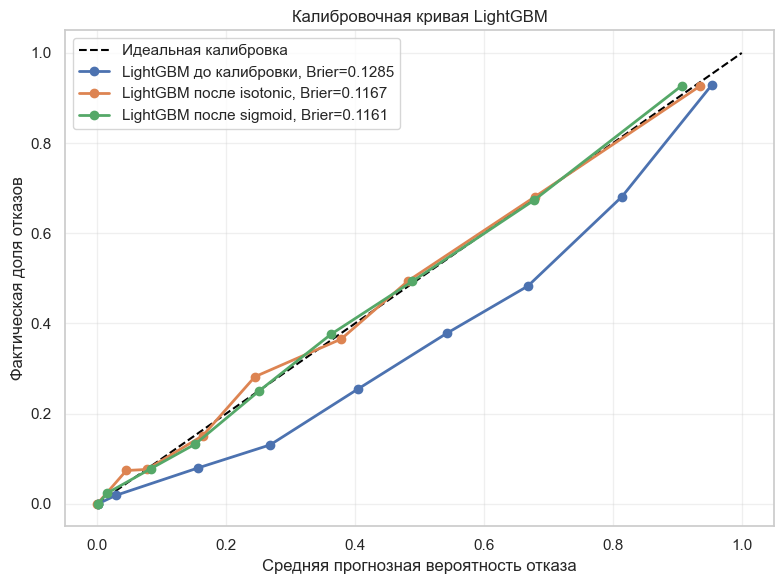

In [115]:
# Строим График калибровки

# n_bins=10: прогнозы делятся на 10 групп по вероятности.
# strategy='quantile' обеспечивает примерно равное
# количество клиентов в каждом интервале.
prob_true_before, prob_pred_before = calibration_curve(
    y_calib,
    probas['до калибровки'],
    n_bins=10,
    strategy='quantile'
)

prob_true_after_istnc, prob_pred_after_istnc = calibration_curve(
    y_calib,
    probas['isotonic'],
    n_bins=10,
    strategy='quantile'
)

prob_true_after_sigm, prob_pred_after_sigm = calibration_curve(
    y_calib,
    probas['sigmoid'],
    n_bins=10,
    strategy='quantile'
)

plt.figure(figsize=(8, 6))

# Идеально калиброванная модель.
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Идеальная калибровка'
)

# Некалиброванная модель.
plt.plot(
    prob_pred_before,
    prob_true_before,
    marker='o',
    linewidth=2,
    label=f"LightGBM до калибровки, Brier={calibration_metrics['до калибровки'][0]:.4f}"
)

# Модель после isotonic calibration.
plt.plot(
    prob_pred_after_istnc,
    prob_true_after_istnc,
    marker='o',
    linewidth=2,
    label=f"LightGBM после isotonic, Brier={calibration_metrics['isotonic'][0]:.4f}"
)

# Модель после isotonic calibration.
plt.plot(
    prob_pred_after_sigm,
    prob_true_after_sigm,
    marker='o',
    linewidth=2,
    label=f"LightGBM после sigmoid, Brier={calibration_metrics['sigmoid'][0]:.4f}"
)

plt.title('Калибровочная кривая LightGBM')
plt.xlabel('Средняя прогнозная вероятность отказа')
plt.ylabel('Фактическая доля отказов')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Результаты калибровки:**
1. Калибровка улучшила вероятностные прогнозы LightGBM: Brier score снизился с 0,1285 до 0,1167 для isotonic и 0,1161 для sigmoid, а LogLoss — с 0,3829 до 0,3529 и 0,3524 соответственно.
2. На графике исходная модель преимущественно завышает вероятность отмены: её кривая проходит ниже диагонали. После калибровки обе кривые приблизились к линии идеальной калибровки.
3. Методы показали близкие результаты: **sigmoid** немного лучше по Brier score и LogLoss.

### Поиск порога классификации

- Используя откалиброванную модель и калибровочную выборку, найдите порог классификации, при котором достигается максимальный Incremental Revenue.

- Сделайте выводы о пороге классификации.

In [116]:
threshold_results = []

# Проверим пороги от 0.001 до 0.999
thresholds = np.arange(0.001, 1.000, 0.005)

for threshold in thresholds:
    metrics = calculate_booking_metrics(
        y_true=y_calib,
        y_proba=calib_proba_sigm,
        threshold=threshold
    )

    threshold_results.append({
        'threshold': threshold,
        **metrics
    })

threshold_results = pd.DataFrame(threshold_results)

best_threshold_row = threshold_results.loc[
    threshold_results['ir'].idxmax()
]

best_threshold = float(best_threshold_row['threshold'])

display(threshold_results.sort_values('ir', ascending=False).head())
print('Лучший порог:', round(best_threshold, 4))
print('IR на calibration:', best_threshold_row['ir'])
print('Относительный IR на calibration:', round(best_threshold_row['ir_relative'],3))

,threshold,accuracy,precision,recall,f1,TN,FP,FN,TP,ir,ir_relative
87,0.436,0.826301,0.712175,0.691337,0.701601,3671,487,538,1205,97127000,62.353829
83,0.416,0.822572,0.695506,0.710270,0.702810,3616,542,505,1238,96808000,62.149036
84,0.421,0.823250,0.699090,0.705106,0.702085,3629,529,514,1229,96752000,62.113085
74,0.371,0.813930,0.660050,0.763052,0.707823,3473,685,413,1330,96657500,62.052418
90,0.451,0.827317,0.721542,0.676420,0.698253,3703,455,564,1179,96568000,61.994960


Лучший порог: 0.436
IR на calibration: 97127000.0
Относительный IR на calibration: 62.354


**Выбор порога классификации:**

- Лучший порог среди проверенных значений — **0,436**: при вероятности отмены не ниже 43,6 % модель прогнозирует отмену бронирования.
- На калибровочной выборке этот порог обеспечивает максимальный IR — 97 127 000 и относительный IR — 62,35.
- Accuracy составляет — 0,8263, Precision – 0,7122, Recall — 0,6913, F1 — 0,7016. Модель обнаружила 1205 отмен, пропустила 538 и сформировала 487 ложных тревог.
- Близкие пороги также дают сопоставимый IR.

### Анализ матрицы классификаций

Оцените стабильность модели на тестовых данных.
- Постройте:
    - матрицу ошибок на калибровочных данных;
    - матрицу ошибок на тестовых данных.

- Посчитайте IR на калибровочных и на тестовых данных.

- Сделайте вывод о стабильности модели.

In [117]:
# Вероятности отмены на test-выборке
test_proba = calib_lgbm_sigm.predict_proba(X_test)[:, 1]

# получение метрик на тесте
test_metrics = calculate_booking_metrics(
    y_true=y_test,
    y_proba=test_proba,
    threshold=best_threshold
)

test_threshold_result = pd.DataFrame(
    {
        'Calibration': [
            best_threshold_row['accuracy'],
            best_threshold_row['precision'],
            best_threshold_row['recall'],
            best_threshold_row['ir'],
            best_threshold_row['ir_relative']
        ],
        'Test': [
            test_metrics['accuracy'],
            test_metrics['precision'],
            test_metrics['recall'],
            test_metrics['ir'],
            test_metrics['ir_relative']
        ]
    },
    index=[
        'accuracy',
        'precision',
        'recall',
        'ir',
        'ir_relative'
    ]
)

display(test_threshold_result.style
    .format(
        '{:.4f}',
        subset=pd.IndexSlice[
            ['accuracy', 'precision', 'recall'], :
        ]
    )
    .format(
        lambda x: f'{x:,.0f}'.replace(',', ' '),
        subset=pd.IndexSlice[['ir'], :]
    )
    .format(
        '{:.2f}',
        subset=pd.IndexSlice[['ir_relative'], :]
    )
)

,Calibration,Test
accuracy,0.8263,0.9183
precision,0.7122,0.8693
recall,0.6913,0.8013
ir,97 127 000,119 482 000
ir_relative,62.35,64.30


In [118]:
# Получение прогнозов классов
# 1 — клиент может отменить бронирование
# 0 — клиент подтвердит бронирование
calib_pred = (calib_proba_sigm >= best_threshold).astype(int)
test_pred = (test_proba >= best_threshold).astype(int)

# Матрица ошибок на calibration
cm_calib = confusion_matrix(
        y_calib,
        calib_pred,
        labels=[0, 1]
    )

# Матрица ошибок на test
cm_test = confusion_matrix(
        y_test,
        test_pred,
        labels=[0, 1]
    )

print(f'Матрика ошибок на calibration: \n{cm_calib}')
print(f'Матрика ошибок на test: \n{cm_test}')

Матрика ошибок на calibration: 
[[3671  487]
 [ 538 1205]]
Матрика ошибок на test: 
[[4209  182]
 [ 300 1210]]


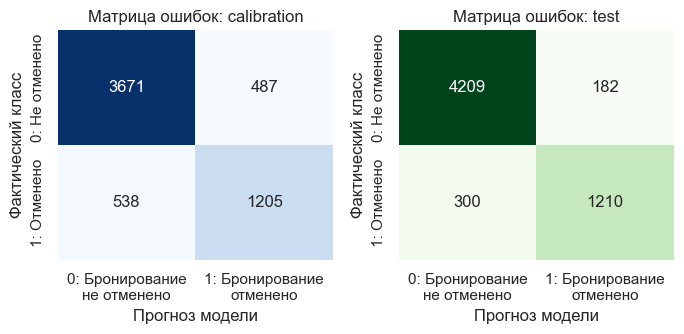

In [119]:
# графическое отображение матриц ошибок
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(7, 3.5)
)

x_labels = [
    '0: Бронирование\nне отменено',
    '1: Бронирование\nотменено'
]
y_labels = [
    '0: Не отменено',
    '1: Отменено'
]

plots = [
    (cm_calib, 'calibration', 'Blues'),
    (cm_test, 'test', 'Greens')
]

for ax, (cm, name, cmap) in zip(axes.flat, plots):
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap=cmap,
        cbar=False,
        ax=ax,
        xticklabels=x_labels,
        yticklabels=y_labels
    )

    ax.set(
        title=f'Матрица ошибок: {name}',
        xlabel='Прогноз модели',
        ylabel='Фактический класс'
    )
    
    ax.tick_params(axis='x', labelrotation=0)
    
plt.tight_layout()
plt.show()

**Вывод о стабильности модели:**

- При фиксированном пороге **0,436** модель сохранила качество на тестовой выборке и показала улучшение метрик: Accuracy выросла с 0,8263 до 0,9183, Precision — с 0,7122 до 0,8693, Recall — с 0,6913 до 0,8013.
- Количество ложных тревог снизилось с 487 до 182, а пропущенных отмен — с 538 до 300. При этом число правильно обнаруженных отмен практически сохранилось: 1205 на calibration и 1210 на test, хотя фактических отмен на тесте было меньше.
- IR увеличился со 97,127 млн до 119,482 млн. Относительный IR остался близким: 62,35 на calibration и 64,30 на test, что указывает на устойчивость бизнес-результата между двумя периодами.
- Таким образом, признаков ухудшения при переносе модели на тестовый период не выявлено.

### Фиксирование итоговой модели

- Зафиксисруйте лучшую модель и найденный порог.


In [120]:
best_model = calib_lgbm_sigm
display(best_model)
print(f'Лучший найденный порог: {round(best_threshold,4)}')

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step...verbose=-1))])
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=2000)
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",True
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn

Лучший найденный порог: 0.436


### Анализ важности признаков

- Оцените важность признаков с помощью любого подходящего инструмента:
  - feature_importances;
  - SHAP;
  - встроенной в модель собственной функции оценки важности.

- Сделайте выводы о влиянии признаков на целевую переменную.

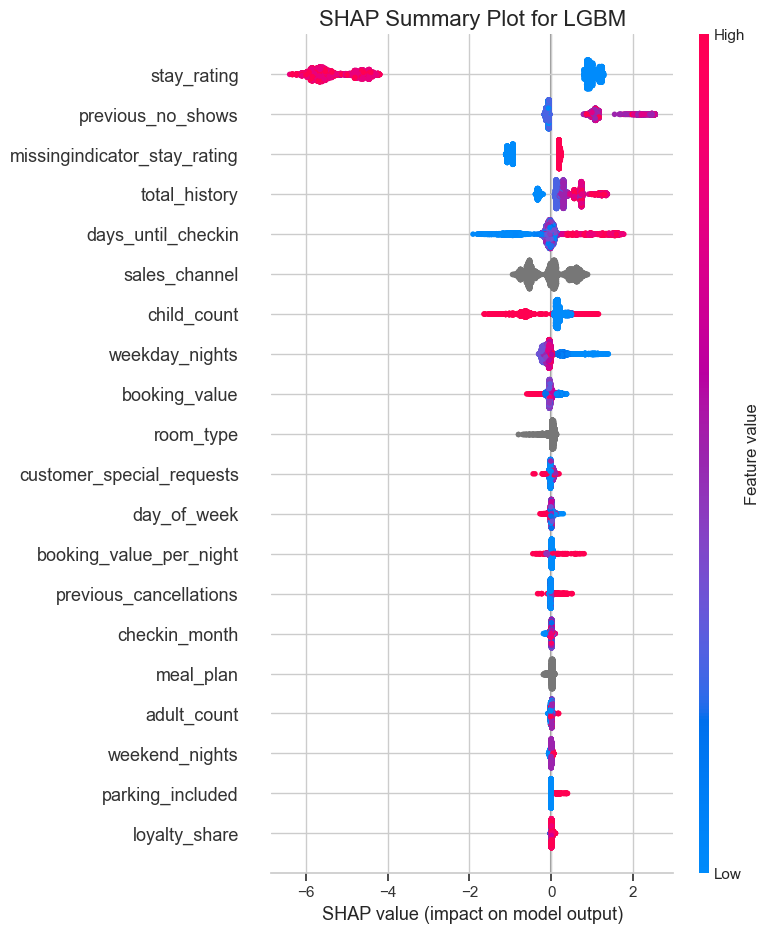

In [121]:
# Берём компоненты обученного пайплайна, т.к. SHAPE не поддерживает обертку CalibClassCV
preprocessor = best_lgbm_pipeline.named_steps['preprocessor']
model = best_lgbm_pipeline.named_steps['model']

# Модель получает преобразованные признаки
X_transformed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

# Создаём explainer и вычисляем SHAP-значения
explainer = shap.TreeExplainer(model)
shap_values_lgbm = explainer(X_transformed)


# Summary Plot для всех признаков
plt.figure(figsize=(7, 6))
shap.summary_plot(
    shap_values_lgbm,
    X_transformed,
    feature_names=feature_names,
    show=False
)
plt.title("SHAP Summary Plot for LGBM", fontsize=16)
plt.tight_layout()
plt.show()

**Вывод по SHAP-анализу:**

1. Рейтинг проживания (`stay_rating`) — наиболее влиятельный признак. Высокие значения существенно снижают прогнозируемый риск отмены, а низкие значения повышают его. Однако низкие значения могут включать пропуски, заполненные числом −1: их нельзя автоматически интерпретировать как низкую оценку клиента.
2. История незаездов (`previous_no_shows`) занимает второе место по важности: большие значения повышают прогнозируемый риск отмены. Количество предыдущих отмен (`previous_cancellations`) также преимущественно повышает риск, но влияет заметно слабее.
3. Наличие или отсутствие рейтинга (`missingindicator_stay_rating`) существенно влияет на прогноз. Отсутствие оценки смещает прогноз в сторону отмены, а наличие — в сторону сохранения бронирования.
4. Объём истории клиента (`total_history`) занимает четвёртое место по важности: большие значения преимущественно повышают прогнозируемый риск отмены, небольшие — снижают.
5.  Время до заезда (`days_until_checkin`) имеет выраженное влияние: длительный интервал между бронированием и заездом повышает прогнозируемый риск отмены, короткий — снижает его.
6. Канал продаж (`sales_channel`) входит в число значимых факторов и может смещать прогноз в обе стороны.
7. Среди менее значимых факторов большее количество детей (`child_count`) преимущественно снижает риск. Небольшое количество будних ночей (`weekday_nights`) связано с повышением риска. Индикатор онлайн-бронирования также преимущественно смещает прогноз в сторону отмены.
8. Стоимость бронирования (`booking_value`) и тип номера (`room_type`) замыкают десятку наиболее важных признаков. Высокая стоимость преимущественно смещает прогноз в сторону сохранения бронирования. Для типа номера определить влияние конкретных категорий по этому графику нельзя. Специальные пожелания, месяц заезда, количество взрослых, парковка и остальные признаки имеют сравнительно небольшие вклады..

## Этап 3: расчёт экономической эффективности модели

Оцените, насколько выгодно внедрять выбранную модель в работу отеля. Для этого нужно выяснить, какой экономический эффект даёт модель и укладываются ли ключевые метрики в заданный уровень.

Если расчёты покажут, что какой-либо показатель не достигает необходимого уровня, то это сигнал к доработке модели. Возможно, вам нужно пересмотреть порог классификации, добавить новые признаки, поменять модель, по-другому предобработать исходные данные — экспериментируйте!

- Шаг 1: подготовка данных. Подготовьте данные для расчётов. Данные для показателей до внедрения модели рассчитывайте с использованием тестовых данных `y_test`, данные после внедрения получите с помощью предсказаний модели `y_pred`.

- Шаг 2: расчёт показателей до и после внедрения модели. Вычислите:
  - Долю отмен бронирования до и после внедрения модели;
  - Загрузку отеля до и после внедрения модели;
  - IR.

- Шаг 3: расчёт динамики показателей. Вычислите:
  - Динамику доли отмен бронирования;
  - Динамику загрузки отеля;
  - Относительный IR — на сколько процентов `IR_после` выше, чем `IR_до`.


Ваша модель должна достигнуть следующих результатов:

- Доля отмен после внедрения модели — 10%

- Загрузка отеля не должна уменьшиться больше чем на 8% после внедрения модели.

- Относительный IR должен составить не менее 50%.

Сделайте выводы о том, получилось ли достичь целевых показателей для бизнеса.


In [122]:
def economic_efficiency(y_true, y_pred):
    # Матрица ошибок:
    # [[TN, FP],
    #  [FN, TP]]
    # TN — модель приняла бронь, гость приехал. Номер занят.
    # FN — модель приняла бронь, гость отменил. Номер пуст.
    # FP — модель отказала, хотя гость приехал бы. Номер пуст.
    # TP — модель отказала, и гость действительно отменил бы.
    TN, FP, FN, TP = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # число бронирований до модели / число доступных номеров
    total = len(y_true) 

    ir, ir_relat = ir_function(y_true, TN, FP, FN, TP)

    # доля отмен до модели
    cancel_ratio_beforev = y_true.sum() / total
    # доля отмен после внедрения модели
    cancel_ratio_after = FN / total # можно исопльзовать тоже значение total, т.к размерность y_pred=y_true

    # Динамика доли отмен бронирования
    cancellation_dynamics = (cancel_ratio_beforev - cancel_ratio_after) * 100 / cancel_ratio_beforev
    
    # Загрузка отеля до
    # занятые номер до: все_бронирования - отмененные
    occupancy_before = (total - y_true.sum()) / total
    # Загрузка отеля после внедения модели
    # занятые номер после: TN (модель приняла бронь, гость приехал)
    occupancy_after = TN / total
    
    # Динамика загрузки
    occupancy_dynamics = (occupancy_before - occupancy_after) * 100 / occupancy_before
    
    return {
        'ir': ir,
        'ir_relative': ir_relat,
        'cancel_ratio_beforev': cancel_ratio_beforev,
        'cancel_ratio_after': cancel_ratio_after,
        'cancellation_dynamics': cancellation_dynamics,
        'occupancy_before': occupancy_before,
        'occupancy_after': occupancy_after,
        'occupancy_dynamics': occupancy_dynamics
    }

In [123]:
# Классы с учетом выбранного порога
y_pred = (test_proba >= best_threshold).astype(int)

ee = economic_efficiency(y_test, y_pred)
econom_effect = pd.DataFrame([ee], index=['Значение']).T
econom_effect = econom_effect.rename(index={
    'ir': 'Прирост дохода',
    'ir_relative': 'Относительный прирост дохода',
    'cancel_ratio_beforev': 'Доля отмен до модели',
    'cancel_ratio_after': 'Доля отмен после модели',
    'cancellation_dynamics': 'Динамика отмен',
    'occupancy_before': 'Загрузка отеля до',
    'occupancy_after': 'Загрузка отеля после модели',
    'occupancy_dynamics': 'Динамика загрузки отеля'
})
display(econom_effect.style
    .format(
        lambda x: f'{x:,.0f}'.replace(',', ' '),
        subset=pd.IndexSlice[['Прирост дохода'], :]
    )
    .format(
        '{:.2f}',
        subset=pd.IndexSlice[['Относительный прирост дохода', 'Динамика отмен', 'Динамика загрузки отеля'], :]
    )
     .format(
            '{:.4f}',
            subset=pd.IndexSlice[['Доля отмен до модели', 'Доля отмен после модели', 'Загрузка отеля до', 'Загрузка отеля после модели'], :]
        )
)

,Значение
Прирост дохода,119 482 000
Относительный прирост дохода,64.30
Доля отмен до модели,0.2559
Доля отмен после модели,0.0508
Динамика отмен,80.13
Загрузка отеля до,0.7441
Загрузка отеля после модели,0.7133
Динамика загрузки отеля,4.14


**Выводы по модели:**
Модель показывает следующие результаты:
- доля отмен после внедрения модели — 5,1 %;
- загрузка отеля уменьшилась на 4,14 % после внедрения модели;
- относительный IR составляет 64 %.

Даныне показатели соответсвуют требования бизнеса. Значит модель можно рекомендовать к применению

## Этап 4: выводы по проекту

Выводы должны состоять из двух логически связанных разделов:

- «Проделанная работа» — описание этапов и решений;

- «Бизнес‑выводы» — интерпретация результатов и рекомендации.

В каждом разделе опишите результаты без избыточной детализации, с опорой на факты и цифры.

### Выводы о проделанной работе

В этом разделе опишите основные этапы проделанной работы по построению модели. Опишите, как проходили следующие шаги:
- Подготовка данных;
- Моделирование;
- Оценка метрик;
- Анализа важности факторов.

1. Для подготовки данных, они были загружены из БД посредством SQLAlchemy.
2. Были загружены данные по бронированиям и по отзывам клиентов
3. Проведен краткий анализ обеих таблиц, который выявил:
    - в Таблице бронировнаий обнаружено 4608 дубликатов (13,3 % от всего объема), которые были удалены;
    - проупуски в данных не выявлены;
    - выявлены выбросы у признака `adult_count`. У остальных признаков завышенные значения не считаются выбросами, т.к. соответсвуют значению признака;
    - в ходе анализ признака `adult_count` выявлены аномальные значения 100, 200 и 300, кратные 100, которые являются ошибкой масштаба и скорректированы делением на 100;
    - в признаке `meal_plan` выявлены редакционные ошибки в данных, которые были исправлены;
    - исключены строки с нулевыми стоимостями бронирования.
4. Была произведено объединение таблицы бронирования и отзывов:
   - проверка показала, что каждому `booking_id` в таблице отзывов соответствует только один `customer_id`;
   - конфликтующих связей не обнаружено;
   - для одной брони может существовать до четырёх отзывов, поэтому для присоединения `customer_id` был сформирован отдельный справочник уникальных пар `booking_id – customer_id`;
   - после объединения число строк не изменилось: таблица сохранила 29 504 записи, что подтверждает отсутствие размножения бронирований при merge;
   - `customer_id` удалось определить для 71,2% бронирований$
   - для 8 850 записей клиент не найден в таблице отзывов, поэтому признаки на основе предыдущих отзывов для них отсутствовуют.
5. Созданы новые признаки истории клиента и параметров проживания: число прошлых бронирований (`total_history`), доля бронирований, завершившихся заселением (`loyalty_share`), длительность проживания (`total_nights`) и стоимость брони за ночь (`booking_value_per_night`).
Добавлены признаки наличия текста предыдущего отзыва (`has_review_text`), его тональности (`sentiment_score`) и расхождения тональности с оценкой клиента (`rating_sentiment_gap`).
6. В обединенной таблице распределение целевой переменной составляет:
    "нет_отказа" – 21 012
    "отказ_брони" – 8 492.
Соотношение примерно 2.47:1 – есть выраженный дисбаланс.
8. С учетом определенного дисбаланса при обучении модели использовались метрики, чувствительные к редкому классу, и методы компенсации дисбаланса.
9. Анализ корреляции признаков с целевой переменной покзаал:
  - наибольшую связь с `booking_status` показывают наличие текста предыдущего отзыва (`has_review_text`, PhiK = 0.572), его тональность (`sentiment_score`, 0.437) и срок до заезда (`days_until_checkin`, 0.400);
    - менее выраженная связь наблюдается у лояльности клиента (`loyalty_share`, 0.207), числа будних ночей (`weekday_nights`, 0.200), предыдущих отмен (`previous_cancellations`, 0.196) и общей длительности проживания (`total_nights`, 0.187).
    - наименьшую связь среди рассмотренных признаков имеет стоимость за ночь (`booking_value_per_night`, 0.016).

9. При моделировании были сравнены две модели **LightGBM Optuna** и **Random Forest**
10. **LightGBM Optuna** показала лучшие средние результаты на временной кросс-валидации по основной бизнес-метрике IR и по большинству метрик классификации:
    - Средний IR равен 31,15 млн. Это на 0,96 млн выше, чем у Random Forest Optuna, и на 1,34 млн выше, чем у исходной LightGBM.
    - Средний относительный IR равен 58,81 против 56,97 у Random Forest Optuna.
    - У модели лучшие средние Accuracy (0,7993), Recall (0,7952) и F1 (0,6998).
    - После оптимизации разброс IR между фолдами снизился: стандартное отклонение уменьшилось с 4,04 млн до 3,56 млн.
11. Random Forest Optuna заняла второе место по среднему IR. Её Precision почти не отличается от LightGBM Optuna (0,6253 против 0,6248).
12. Optuna улучшила обе модели. У Random Forest Recall вырос с 0,6773 до 0,7692, F1 — с 0,6626 до 0,6898, а IR — с 28,21 млн до 30,19 млн.
13. Итоговая модель выбрана **LightGBM Optuna**.
14. Калибровка улучшила вероятностные прогнозы LightGBM: Brier score снизился с 0,1285 до 0,1167 для isotonic и 0,1161 для sigmoid, а LogLoss — с 0,3829 до 0,3529 и 0,3524 соответственно.
15. Методы показали близкие результаты: **sigmoid** немного лучше по Brier score и LogLoss.
16. Лучший порог среди проверенных значений — **0,436**: при вероятности отмены не ниже 43,6 % модель прогнозирует отмену бронирования.
17. На калибровочной выборке этот порог обеспечивает максимальный **IR** — 97 127 000 и относительный IR — 62,35, **Accuracy** составляет 0,8263, **Precision** – 0,7122, **Recall** — 0,6913, **F1** — 0,7016. Модель обнаружила 1205 отмен, пропустила 538 и сформировала 487 ложных тревог.
18. При фиксированном пороге **0,436** модель сохранила качество на тестовой выборке и показала улучшение метрик:
    - **Accuracy** выросла с 0,8263 до 0,9183, **Precision** — с 0,7122 до 0,8693, **Recall** — с 0,6913 до 0,8013;
    - Количество ложных тревог снизилось с 487 до 182, а пропущенных отмен — с 538 до 300. При этом число правильно обнаруженных отмен практически сохранилось: 1205 на calibration и 1210 на test, хотя фактических отмен на тесте было меньше;
    - **IR** увеличился со 97,127 млн до 119,482 млн, **Относительный IR** остался близким: 62,35 на calibration и 64,30 на test, что указывает на устойчивость бизнес-результата между двумя периодами.

19. Рейтинг проживания (`stay_rating`) — наиболее влиятельный признак. Высокие значения существенно снижают прогнозируемый риск отмены, а низкие значения повышают его. Однако низкие значения могут включать пропуски, заполненные числом −1: их нельзя автоматически интерпретировать как низкую оценку клиента.
20. История незаездов (`previous_no_shows`) занимает второе место по важности: большие значения повышают прогнозируемый риск отмены. Количество предыдущих отмен (`previous_cancellations`) также преимущественно повышает риск, но влияет заметно слабее.
21. Наличие или отсутствие рейтинга (`missingindicator_stay_rating`) существенно влияет на прогноз. Отсутствие оценки смещает прогноз в сторону отмены, а наличие — в сторону сохранения бронирования.
22. Объём истории клиента (`total_history`) занимает четвёртое место по важности: большие значения преимущественно повышают прогнозируемый риск отмены, небольшие — снижают
23. Время до заезда (`days_until_checkin`) имеет выраженное влияние: длительный интервал между бронированием и заездом повышает прогнозируемый риск отмены, короткий — снижает его.
24.  Канал продаж (`sales_channel`) входит в число значимых факторов и может смещать прогноз в обе стороны.
25.  Среди менее значимых факторов большее количество детей (`child_count`) преимущественно снижает риск. Небольшое количество будних ночей (`weekday_nights`) связано с повышением риска. Индикатор онлайн-бронирования также преимущественно смещает прогноз в сторону отмены.
26.  Стоимость бронирования (`booking_value`) и тип номера (`room_type`) замыкают десятку наиболее важных признаков. Высокая стоимость преимущественно смещает прогноз в сторону сохранения бронирования. Для типа номера определить влияние конкретных категорий по этому графику нельзя. Специальные пожелания, месяц заезда, количество взрослых, парковка и остальные признаки имеют сравнительно небольшие вклады..

### Выводы по анализу эффективности модели

В этом разделе ответьте на вопрос: «Что это значит для бизнеса?» Для этого интерпретируйте результаты вашей работы, дайте им экономическую оценку, а заказчику — рекомендации.

Включите следующие пункты:

- Итоговая оценка достижения цели:
  - Вспомните цель проекта и определите, достигнута ли она. Аргументируйте свой ответ.

- Результаты по ключевым метрикам. Для каждого показателя приведите:
  - Значение до внедрения модели.
  - Значение после внедрения.
  - Изменение в процентах с расчётом по формуле.
  
- Сообщите заказчику, достигнуты ли целевые показатели по метрикам.

- Анализ важности признаков:
  - Опишите для заказчиков основные 10 признаков, влияющих на резкие отмены заказов.
  - Кратко объясните, как они влияют на целевую переменную. Пример такого объяснения: «лояльность клиента снижает риск отмены на 15%».

- Рекомендации для бизнеса:
  - Предложите 2–3 конкретных шага по оптимизации работы сети отелей.

***Оснвоная цель проекта:***
 - Разработать ML‑модель, прогнозирующую вероятность отмены бронирования. Она должна минимизировать финансовые потери сети отелей и по возможности повышать загрузку номеров. Её задача — предсказывать вероятность отмены брони по входным данным.
 - Экономическая эффективность модели оценивается по треми показателям:
    - динамика доли отмен бронирования: доля отмен бронировнаия должна стать не больше 10 %;
    - динамика загрузки отелей: загрзука отеля не должна уменьшиться больше чем на 8 %;
    - прирост дохода благодаря модели: относительный прирост должен быть не менее 50 %.

Итоговая модель соответсвует требуемым показателям:
    - доля отмен после внедрения модели — 5,08 %;
    - загрузка отеля уменьшилась на 4,14 % после внедрения модели;
    - относительный IR составляет 64,3 %.

Результаты по ключевым метрикам:
 - Прирост дохода (IR) – 119 482 000 руб.;
 - Относительный прирост дохода (Относительный IR) – 64.30 %;
 - Доля отмен до внедрения модели –	25,59 %;
 - Доля отмен после модели – 5,08 %;
 - Динамика отмен умееньшилась на –	80,13 %;
 - Загрузка отеля до внедрения модели – 74,41 %;
 - Загрузка отеля после модели	– 71,33 %;
 - Динамика загрузки отеля уменьшилась на –	4,14 %.

**Целевые показатели по метрикам достигнуты**

***Анализ важности признаков***

По результатам **SHAP**-анализа модели LGBM выделены 10 наиболее значимых признаков для прогнозирования отмены бронирования:
1. Оценка проживания (`stay_rating`) — наиболее значимый признак: высокие оценки существенно снижают прогнозируемый риск отмены, низкие — повышают.
2. Число предыдущих незаездов (`previous_no_shows`) — высокие значения заметно повышают прогнозируемый риск отмены.
3. Отсутствие оценки проживания (`missingindicator_stay_rating`) — пропуск оценки повышает прогноз отмены, наличие оценки — снижает.
4. Количество дней до заезда (`days_until_checkin`) — ранние бронирования чаще получают повышенный прогноз риска; бронирования ближе к дате заезда — пониженный.
5. Объём истории клиента (`total_history`) — большие значения преимущественно повышают прогноз отмены.
6. Время до заезда `days_until_checkin` – длительный интервал между бронированием и заездом повышает прогнозируемый риск отмены, короткий — снижает его.
7. Онлайн-бронирование (`sales_channel_онлайн_бронирование`) — наличие этого признака повышает прогнозируемый риск отмены относительно его отсутствия.
8. Количество детей (`child_count`) — более высокие значения преимущественно снижают прогнозируемый риск, хотя влияние неоднородно.
9. Количество будних ночей (`weekday_nights`) — небольшое количество будних ночей повышает прогноз отмены; большие значения преимущественно снижают его.
10. Офлайн-бронирование (`sales_channel_офлайн_бронирование`) — наличие этого признака немного повышает прогноз отмены относительно его отсутствия.
11. Количество предыдущих отмен (`previous_cancellations`) — высокие значения повышают прогнозируемый риск, но вклад признака значительно слабее, чем у лидирующих факторов.

***Рекомендации для бизнеса***
- Напоминать клиентам о предстоящем заезде. Для бронирований, сделанных задолго до поездки, заранее отправлять сообщение с просьбой подтвердить приезд. Если планы изменились, предлагать сразу отменить бронь — это позволит раньше вернуть номер в продажу.
- Протестировать условия гарантии бронирования: для части высокорисковых заказов предложить частичную предоплату или выбор между гибким и более выгодным невозвратным тарифом.
- Использовать прогноз для планирования продаж: регулярно пересчитывать риск по действующим бронированиям и учитывать его при подготовке рекламных предложений на даты с ожидаемым недозаполнением. Решения принимать по совокупному прогнозу, а не только по одному признаку или каналу продаж.